Input: a text in Ukrainian, Russian or mixed code, usually a Telegram post. Output: a list of location strings exactly as written in the text. Locations are cities, countries, regions, districts, streets and addresses, and other geographic objects. For example, `Сьогодні з Києва до Хелма вперше вирушив новий поїзд` should return `["Києва", "Хелма"]`. Scoring is F1 over sets of strings.


## What we work with

| File | What it is | Size | Labels |
|---|---|---|---|
| `uk_geo_dataset.csv` | news sentences, Ukr-Synth corpus | 1.01M | machine LOC/ORG/PER spans |
| `ru_geo_dataset.csv` | Lenta.ru news sentences, Nerus corpus | 8.03M | machine LOC/ORG/PER spans |
| `uk_geo_dataset_processed_v1.parquet` | tokens of the same uk corpus | 1.01M | flat O/LOC, no B/I |
| `labeling_sample.csv` | Telegram posts | 26 | manual |
| `test.csv` | Telegram posts | 477 | none |

Train is large, but it is news with machine labels. We are scored on Telegram, and only 26 posts have manual labels.

In [1]:
import ast, json, re, string, sys, unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

DATA = Path("../data")
PROJECT_ROOT = DATA.resolve().parent
RESULTS = PROJECT_ROOT / "results"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.dedup import deduplicate_near
from scripts.label_analysis import boundary_profile, core_form, form_profile, same_core_variants
from scripts.preflight_analysis import cleaning_review, span_recovery
from scripts.target_analysis import FORM_PATTERNS, context_probes, type_profile
from scripts.test_analysis import comparison_text, domain_auc, language_profile, scan_corpus, shingles, tfidf_neighbors, words
from scripts.test_profile import distribution_distances, distributions, feature_row, profile, pseudo_sentences, source_features, strata

pd.set_option("display.max_colwidth", 120, "display.max_rows", 100)

In [2]:
# Official metric of the competition
def hard_processing(text):
    text = re.sub(r"[{re.escape(string.punctuation)}]", "", text)
    text = re.sub(r"\d", "", text)
    text = re.sub(r"\b\w\b\s?", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text.lower()


def comp_metric(y_true, y_pred):
    assert len(y_true) == len(y_pred)
    tp, fp, fn, p = 0.0, 0.0, 0.0, 0.0
    for y_true_sample, y_pred_sample in zip(y_true, y_pred):
        y_true_sample = {hard_processing(s) for s in y_true_sample}
        y_pred_sample = {hard_processing(s) for s in y_pred_sample}
        tp += len(y_true_sample & y_pred_sample)
        fp += len(y_pred_sample - y_true_sample)
        fn += len(y_true_sample - y_pred_sample)
        p += len(y_true_sample)
    precision = tp / (tp + fp) if tp + fp else float(p == 0)
    recall = tp / (tp + fn) if tp + fn else float(p == 0)
    return round(2 * precision * recall / (precision + recall), 8) if precision + recall else 0

In [3]:
TOKEN = re.compile(r"\w+(?:['’ʼ]\w+)*|[^\w\s]")
SPAN = re.compile(r"\((\d+),\s*(\d+)\)")


def parse_spans(value):
    return [(int(a), int(b)) for a, b in SPAN.findall(str(value))]


def tokenize(text):
    return [m.span() for m in TOKEN.finditer(text)]


def clean_spans(text, spans):
    # Merges spans that touch or overlap (a name marked in pieces: Івано + - + Франківськ),
    # trims edge whitespace and drops spans without letters. It never splits a span.
    merged = []
    for a, b in sorted(spans):
        if merged and a <= merged[-1][1]:
            merged[-1] = (merged[-1][0], max(b, merged[-1][1]))
        else:
            merged.append((a, b))
    cleaned = []
    for a, b in merged:
        chunk = text[a:b]
        a, b = a + len(chunk) - len(chunk.lstrip()), b - (len(chunk) - len(chunk.rstrip()))
        if a < b and any(c.isalnum() for c in text[a:b]):
            cleaned.append((a, b))
    return cleaned


def spans_to_bio(offsets, spans):
    tags, misaligned = ["O"] * len(offsets), 0
    for a, b in spans:
        hit = [i for i, (s, e) in enumerate(offsets) if s < b and a < e]
        if not hit or offsets[hit[0]][0] != a or offsets[hit[-1]][1] != b:
            misaligned += 1
        if hit:
            tags[hit[0]] = "B"
            for i in hit[1:]:
                tags[i] = "I"
    return tags, misaligned


def bio_to_strings(text, offsets, tags, merge_adjacent=False):
    out, i = [], 0
    while i < len(tags):
        if tags[i] == "O":
            i += 1
            continue
        j = i + 1
        while j < len(tags) and (tags[j] == "I" or (merge_adjacent and tags[j] != "O")):
            j += 1
        out.append(text[offsets[i][0]:offsets[j - 1][1]])
        i = j
    return out


def normalize_text(text):
    text = unicodedata.normalize("NFKC", text)
    return re.sub(r"\W+", " ", text.lower()).strip()


def normalised_loc_signature(text, spans):
    signature, empty_spans = [], 0
    for a, b in spans:
        assert 0 <= a < b <= len(text)
        entity = normalize_text(text[a:b])
        if entity:
            signature.append((normalize_text(text[:a]), entity, normalize_text(text[b:])))
        else:
            empty_spans += 1
    return tuple(sorted(signature)), empty_spans


assert normalize_text("Київ") == normalize_text("Київ")
assert normalised_loc_signature("Київ", [(0, 5)]) == normalised_loc_signature("Київ", [(0, 4)])
assert normalised_loc_signature("Київ Київ", [(0, 4)]) != normalised_loc_signature("Київ Київ", [(5, 9)])

## 0. Дані

In [4]:
uk = pd.read_csv(DATA / "uk_geo_dataset.csv")
test = pd.read_csv(DATA / "test.csv")
sample = pd.read_csv(DATA / "labeling_sample.csv")
pd.DataFrame({
    name: {"рядків": len(frame), "колонки": ", ".join(frame.columns)}
    for name, frame in {"uk": uk, "test": test, "labeling_sample": sample}.items()
}).T

,рядків,колонки
uk,1010000,"text, loc_markers, org_markers, per_markers, is_valid"
test,477,"text_id, text, locations"
labeling_sample,26,"text, locations, loc_markers"


| Колонка | Опис |
|---|---|
| `text` | Текст, у якому потрібно знайти локації. |
| `loc_markers` | Список координат локацій у тексті: `(початок, кінець)`.|
| `org_markers` | Координати згадок організацій.|
| `per_markers` | Координати згадок людей. |
| `locations` | Список локацій словами, наприклад `["Проспект Бандери"]`. У `labeling_sample.csv` це надані відповіді. У `test.csv` всі значення `[]` — порожні заготовки для прогнозів, а не позначка відсутності локацій. |
| `is_valid` | Позначка поділу українського датасету: `0` — навчання, `1` — валідація. |
| `text_id` | Ідентифікатор тексту в test, за яким можна зіставити текст із прогнозом моделі. |

**Що таке ru dataset?**

`ru_geo_dataset.csv` — російськомовні новинні речення з розміткою сутностей. За описом у `data/README.md`, набір сформований на основі Nerus. Один рядок — одне речення.

| Колонка | Що містить |
|---|---|
| `text` | Саме речення. |
| `loc_markers` | Координати згадок локацій у реченні. |
| `doc_id` | Ідентифікатор документа, з якого взято речення. |
| `sent_id` | Номер речення всередині документа. |

У CSV також є `org_markers` і `per_markers` — координати організацій та людей. Для поточного аналізу локацій завантажуємо чотири колонки з таблиці.

In [5]:
ru = pd.read_csv(DATA / "ru_geo_dataset.csv", usecols=["text", "loc_markers", "doc_id", "sent_id"])
pd.Series({"рядків ru": len(ru), "документів": ru.doc_id.nunique()}).to_frame("кількість")

,кількість
рядків ru,8028840
документів,739190


### Правила цього EDA

- Тут лише описуємо дані: моделі NER не навчаємо, експерименти не проєктуємо — тільки вказівки для них (§10).
- Мітки test не створюємо й не виправляємо. Колонка `test.locations` порожня в усіх рядках (перевірка нижче) — це шаблон для сабміту.
- Для test є автоматичні прогнози **GPT‑6 Luna** (`effort=low`) у `results/test_analysis/gpt_*.jsonl`: одна генерація для всіх дописів test, 26 sample і по 32 випадкові рядки uk/ru. Модель бачила лише текст та інструкцію «повертати назви географічних місць і адрес у формі з тексту, без назв лише всередині організацій чи підписів каналів». Ці прогнози — грубий опис test, а не еталон: на них не навчаємо й не підбираємо пороги.
- Таблиці результатів записуються в `results/` однією останньою клітинкою (§11).

In [6]:
GPT_DIR = RESULTS / "test_analysis"
gpt_inputs = pd.read_json(GPT_DIR / "gpt_inputs.jsonl", lines=True)
gpt_predictions = pd.read_json(GPT_DIR / "gpt_predictions.jsonl", lines=True)
gpt = gpt_inputs.merge(gpt_predictions, on="key", validate="one_to_one")
assert len(gpt) == len(gpt_inputs) == len(gpt_predictions)
gpt_test = gpt.loc[gpt.dataset.eq("test")].copy()

assert test.text_id.is_unique and test.text.notna().all()
test_label_cells = test.locations.map(ast.literal_eval)
pd.Series({
    "рядків test": len(test),
    "порожніх test.locations": int(test_label_cells.map(len).eq(0).sum()),
    **{f"GPT-прогнозів, {name}": count for name, count in gpt.dataset.value_counts().items()},
}).to_frame("кількість")

,кількість
рядків test,477
порожніх test.locations,477
"GPT-прогнозів, test",477
"GPT-прогнозів, uk",32
"GPT-прогнозів, ru",32
"GPT-прогнозів, sample",26


## 1. Цілісність даних і розмітки

### 1.1 Чи є пропуски в `text` і `loc_markers`?

In [7]:
display(pd.DataFrame({
    name: frame[["text", "loc_markers"]].isna().sum()
    for name, frame in {"uk": uk, "ru": ru, "labeling_sample": sample}.items()
}).T)
print("Пропуски text у test:", int(test.text.isna().sum()))

,text,loc_markers
uk,0,0
ru,0,0
labeling_sample,0,0


Пропуски text у test: 0


**Результат.** Пропусків немає в жодному наборі → окрема обробка NaN не потрібна.

### 1.2 Що означають координати в `loc_markers`?

Рядок `"[(0, 16)]"` розбираємо в список пар `(a, b)`: `a` — індекс першого символу назви, `b` — індекс одразу після останнього, тож `text[a:b]` — сама назва. Для `Київ!` спан `Київ` — це `(0, 4)`.

In [8]:
for frame, column in [(uk, "loc_markers"), (uk, "org_markers"), (ru, "loc_markers"), (sample, "loc_markers")]:
    frame[column] = frame[column].map(parse_spans)
sample["locations"] = sample["locations"].map(ast.literal_eval)
row = sample[sample.loc_markers.map(bool)].iloc[0]
pd.DataFrame({"координати": row.loc_markers, "текст спану": [row.text[a:b] for a, b in row.loc_markers]})

,координати,текст спану
0,"(0, 16)",Проспект Бандери


**Результат.** `text[a:b]` дає назву точно в тій формі, що в тексті → рядок для відповіді вирізаємо з оригінального тексту за координатами.

### 1.3 Чи всі спани лежать у межах тексту?

Для кожного LOC-спану перевіряємо `0 ≤ a < b ≤ len(text)`.

In [9]:
span_bounds = pd.DataFrame({
    name: {
        "спанів": int(frame.loc_markers.map(len).sum()),
        "недопустимі координати": sum(not (0 <= a < b <= len(text)) for text, spans in zip(frame.text, frame.loc_markers) for a, b in spans),
    }
    for name, frame in {"uk": uk, "ru": ru, "labeling_sample": sample}.items()
}).T
display(span_bounds)
assert span_bounds["недопустимі координати"].eq(0).all()

,спанів,недопустимі координати
uk,345114,0
ru,3708173,0
labeling_sample,32,0


**Результат.** Недопустимих координат немає серед 345 114 спанів uk, 3 708 173 ru і 32 sample → координатам довіряємо; перевірка лишається як `assert`.

### 1.4 Які дефекти меж є в розмітці?

`no_letters_or_digits` — спан без букв і цифр; `edge_space_or_punct` — пробіл чи пунктуація на краю; `mid_word_boundary` — межа посеред слова. Ознаки можуть перетинатися.

In [10]:
def marker_defects(df):
    c = Counter()
    for text, spans in zip(df["text"], df["loc_markers"]):
        for a, b in spans:
            s = text[a:b]
            c["spans"] += 1
            c["no_letters_or_digits"] += not any(ch.isalnum() for ch in s)
            c["edge_space_or_punct"] += not (s[0].isalnum() and s[-1].isalnum())
            c["mid_word_boundary"] += (a > 0 and text[a - 1].isalnum() and s[0].isalnum()) or (b < len(text) and text[b].isalnum() and s[-1].isalnum())
    return c


defects = pd.DataFrame({"uk": marker_defects(uk), "ru": marker_defects(ru), "sample": marker_defects(sample)}).fillna(0).astype(int)
defects

,uk,ru,sample
spans,345114,3708173,32
no_letters_or_digits,1057,50,0
edge_space_or_punct,5364,16792,0
mid_word_boundary,1516,7712,1


**Результат.** uk: 1 057 спанів без букв, 5 364 з пробілом чи пунктуацією на краю, 1 516 з межею посеред слова; ru: 50 / 16 792 / 7 712. Це до 1,6% спанів, але з такими межами BIO-теги будуть неправильні → чистимо межі (1.5).

### 1.5 Що змінює `clean_spans` і чи це безпечно?

`clean_spans` (клітинка з хелперами) зливає спани, що перекриваються або стоять впритул (`Івано` + `-` + `Франківськ` → `Івано-Франківськ`), обрізає пробіли на краях і відкидає спани без букв і цифр. Рахуємо зміни на всьому uk і ru, потім перевіряємо інваріанти на uk train і ru: чи не загубилися розмічені букви, чи повторний виклик нічого не змінює. Приклади — до 8 рядків на кожну причину плюс незмінені контрольні рядки.

In [11]:
uk["spans"] = [clean_spans(t, s) for t, s in zip(uk.text, uk.loc_markers)]
ru["spans"] = [clean_spans(t, s) for t, s in zip(ru.text, ru.loc_markers)]
sample["spans"] = sample["loc_markers"]
pd.DataFrame({
    name: {
        "spans_before": int(frame.loc_markers.map(len).sum()),
        "spans_after": int(frame.spans.map(len).sum()),
        "span_count_reduction": int(frame.loc_markers.map(len).sum() - frame.spans.map(len).sum()),
        "rows_with_changed_annotations": sum(a != b for a, b in zip(frame.loc_markers, frame.spans)),
    }
    for name, frame in {"uk": uk, "ru": ru}.items()
}).T

,spans_before,spans_after,span_count_reduction,rows_with_changed_annotations
uk,345114,341453,3661,2967
ru,3708173,3706582,1591,1569


In [12]:
cleaning_audits, cleaning_examples = {}, []
for name, frame in {"uk_train": uk.loc[uk.is_valid.eq(0)], "ru": ru}.items():
    summary, examples = cleaning_review(frame, clean_spans)
    cleaning_audits[name] = summary
    cleaning_examples.append(examples.assign(dataset=name))
cleaning_audits = pd.DataFrame(cleaning_audits).T.fillna(0).astype(int)
cleaning_examples = pd.concat(cleaning_examples, ignore_index=True)
display(cleaning_audits)
with pd.option_context("display.max_colwidth", 180):
    display(cleaning_examples.groupby(["dataset", "reason"], sort=False).head(2)[["dataset", "source_index", "reason", "before_strings", "after_strings", "text"]])

,rows,changed_rows,rows_losing_alphanumeric_coverage,merge_rows,punctuation_only_rows,trim_rows
uk_train,1000000,2939,0,2569,1046,203
ru,8028840,1569,0,1507,50,13


,dataset,source_index,reason,before_strings,after_strings,text
0,uk_train,783356,merge,"[Івано, -, Франківська, Бербенескул]","[Івано-Франківська, Бербенескул]","Як вдалося з’ясувати, троє 19-річних мешканців Івано-Франківська ввечері, 22 липня, зійшли на гору Бербенескул."
1,uk_train,590344,merge,"[Івано, -Франківські]",[Івано-Франківські],"У вівторок, 31 грудня, Івано-Франківські олімпійці вирішили нагадати містянам, що здорового способу життя варто дотримуватися 365 днів на рік, і свята не виняток."
8,uk_train,767320,trim,[України також ],[України також],"За словами Олекси Гудими, принаймні сто народних депутатів України також мають намір поставити підписи під таким проханням і передати його Святійшому Отцеві."
9,uk_train,752213,trim,"[Барселоні, на яких ]","[Барселоні, на яких]","Так, зірка на своїй сторінці в Instagram поділилася кількома знімками, зробленими у Барселоні, на яких позує на тлі храму Святого Сімейства."
16,uk_train,944129,punctuation_only,"[Києво, -, Печерської лаври]",[Києво-Печерської лаври],«В наших планах - зробити цей маршрут до Києво-Печерської лаври.
17,uk_train,47169,punctuation_only,"[., Бершадського району]",[Бершадського району],Її чоловіком був директор цукрового заводу в с. Красносілка Бершадського району.
24,uk_train,72943,unchanged_with_LOC,[України],[України],Таке рішення для збірної України матиме негативні наслідки.
25,uk_train,321855,unchanged_with_LOC,[Росії в ОЕС У],[Росії в ОЕС У],Перші комерційні поставки електроенергії з Росії в ОЕС України почалися з початку жовтня 2019р.
32,uk_train,84012,unchanged_without_LOC,[],[],"Тому документи податковим органам необхідно надані в термін ""із запасом"" до закінчення термінів перевірки (відповідно до посвідчень на перевірку в кожного що перевіряє)."
33,uk_train,16525,unchanged_without_LOC,[],[],"Це оновлення стосується і повернення дітей до школи після самоізоляції та пацієнтів, які йдуть на планову госпіталізацію."


**Результат.** Очищення змінює 2 967 текстів uk (спанів 345 114 → 341 453) і 1 569 текстів ru (−1 591 спан). Розмічені букви й цифри не губляться, повторний виклик дає той самий результат → BIO будуємо з очищених `spans`. Ризик лишається в злитті двох різних назв через дефіс (`Київ-Одеса`); приклади для ручного перегляду зберігаються в `results/preflight/cleaning_review_examples.csv`.

### 1.6 Скільки рядків uk закінчуються підписом TCH і що в них розмічено?

Шаблон `… - Київ - TCH.`: назва з підпису потрапляє в LOC-мітку.

In [13]:
uk["tch_footer"] = uk.text.str.contains(r"TCH\.?\s*$")
display(pd.Series({
    "рядків із TCH": int(uk.tch_footer.sum()),
    "усіх LOC-спанів у цих рядках": int(uk.loc[uk.tch_footer, "loc_markers"].map(len).sum()),
}).to_frame("кількість"))
footer_examples = uk.loc[uk.tch_footer, ["text", "loc_markers"]].head(3).copy()
footer_examples["locations"] = [[t[a:b] for a, b in spans] for t, spans in zip(footer_examples.text, footer_examples.loc_markers)]
with pd.option_context("display.max_colwidth", None):
    display(footer_examples[["text", "locations"]])

,кількість
рядків із TCH,9249
усіх LOC-спанів у цих рядках,9714


,text,locations
235,"Під час ""кривавого"" затемнення на Місяць впав метеорит - Наука та IT - TCH.",[Місяць]
405,Нічна різанина в центрі Одеси обірвала двоє життів - новини України - Укрaїнa - TCH.,"[Одеси, України, Укрaїнa]"
500,У супермаркеті Києва невідомий погрожував українськомовному покупцю - Київ - TCH.,"[Києва, Київ]"


**Результат.** 9 249 рядків uk (0,9%) із 9 714 LOC-спанами. Крім назви в підписі, у них є й корисні згадки з тексту новини → викидати весь рядок шкода; краще вирізати підпис або зняти мітку лише з нього.

### 1.7 Які теги в похідному `uk_geo_dataset_processed_v1.parquet`?

In [14]:
parquet_path = DATA / "uk_geo_dataset_processed_v1.parquet"
if parquet_path.exists():
    parquet_labels = pd.read_parquet(parquet_path, columns=["labels"])["labels"].head(5000)
    parquet_tags = Counter(tag for values in parquet_labels for tag in (json.loads(values) if isinstance(values, str) else values))
    display(pd.Series(parquet_tags).to_frame("токенів у перших 5 000 рядках"))
else:
    print("Локального parquet немає; перевірку пропущено.")

,токенів у перших 5 000 рядках
O,86060
LOC,2156


**Результат.** Лише `O` і `LOC`, без B/I → дві суміжні назви там не розрізнити; BIO будуємо самі з `loc_markers` (7.2).

## 2. Дублікати та витоки

### 2.1 Який ключ використовувати для пошуку повторів?

`normalize_text`: NFKC → нижній регістр → усі не-словесні символи в один пробіл. Порівнюємо його з точним текстом і зі старим ключем без NFKC. NFKC зводить різні Unicode-записи однієї літери (`й` одним символом і `и` + знак), але не зводить відмінки (`Київ` ≠ `Києві`) і не робить латинську `a` кириличною.

In [15]:
uk["norm"] = uk.text.map(normalize_text)


def legacy_normalize(text):
    return re.sub(r"\W+", " ", text.lower()).strip()


nfkc_impact = []
for name, frame in {"uk": uk, "ru": ru, "test": test}.items():
    nfkc_texts = frame.text.map(lambda s: unicodedata.normalize("NFKC", s))
    nfkc_impact.append({
        "dataset": name, "rows": len(frame),
        "exact": int(frame.text.duplicated().sum()),
        "NFKC_only": int(nfkc_texts.duplicated().sum()),
        "previous_key": int(frame.text.map(legacy_normalize).duplicated().sum()),
        "NFKC_key": int(nfkc_texts.map(legacy_normalize).duplicated().sum()),
        "rows_changed_by_NFKC": int(frame.text.ne(nfkc_texts).sum()),
    })
del nfkc_texts
nfkc_impact = pd.DataFrame(nfkc_impact).set_index("dataset")
nfkc_impact

,rows,exact,NFKC_only,previous_key,NFKC_key,rows_changed_by_NFKC
dataset,,,,,,
uk,1010000,2454,2458,3786,3786,14585
ru,8028840,523501,523507,537412,537398,8374
test,477,0,0,0,0,133


In [16]:
uk_key_comparison = pd.DataFrame({"previous_key": uk.text.map(legacy_normalize), "NFKC_key": uk.norm})
merged_keys = uk_key_comparison.groupby("NFKC_key", sort=False).previous_key.nunique().loc[lambda s: s > 1]
split_keys = uk_key_comparison.groupby("previous_key", sort=False).NFKC_key.nunique().loc[lambda s: s > 1]
display(pd.Series({
    "rows_with_changed_key": int(uk_key_comparison.previous_key.ne(uk_key_comparison.NFKC_key).sum()),
    "new_groups_merging_previous_keys": len(merged_keys),
    "previous_groups_split_by_NFKC": len(split_keys),
}).to_frame("count"))
nfkc_examples = pd.concat([
    uk.loc[uk.norm.isin(merged_keys.head(1).index), ["text"]].assign(kind="NFKC об'єднав"),
    uk.loc[uk_key_comparison.previous_key.isin(split_keys.head(1).index), ["text"]].assign(kind="NFKC розділив"),
]).join(uk_key_comparison)
nfkc_examples["unicode_escape"] = nfkc_examples.text.map(lambda s: s.encode("unicode_escape").decode("ascii"))
with pd.option_context("display.max_colwidth", None):
    display(nfkc_examples)

,count
rows_with_changed_key,5322
new_groups_merging_previous_keys,4
previous_groups_split_by_NFKC,4


,text,kind,previous_key,NFKC_key,unicode_escape
133398,"«Інноватика в сучасній освіті» – єдиний професійний форум освітніх, наукових і науково-технічних інновацій в Україні, на якому широко представлені інноваційні досягнення галузі освіти.",NFKC об'єднав,інноватика в сучасній освіті єдиний професійний форум освітніх наукових і науково технічних інновацій в україні на якому широко представлені інноваційні досягнення галузі освіти,інноватика в сучасній освіті єдиний професійний форум освітніх наукових і науково технічних інновацій в україні на якому широко представлені інноваційні досягнення галузі освіти,"\xab\u0406\u043d\u043d\u043e\u0432\u0430\u0442\u0438\u043a\u0430 \u0432 \u0441\u0443\u0447\u0430\u0441\u043d\u0456\u0439 \u043e\u0441\u0432\u0456\u0442\u0456\xbb \u2013 \u0454\u0434\u0438\u043d\u0438\u0439 \u043f\u0440\u043e\u0444\u0435\u0441\u0456\u0439\u043d\u0438\u0439 \u0444\u043e\u0440\u0443\u043c \u043e\u0441\u0432\u0456\u0442\u043d\u0456\u0445, \u043d\u0430\u0443\u043a\u043e\u0432\u0438\u0445 \u0456 \u043d\u0430\u0443\u043a\u043e\u0432\u043e-\u0442\u0435\u0445\u043d\u0456\u0447\u043d\u0438\u0445 \u0456\u043d\u043d\u043e\u0432\u0430\u0446\u0456\u0439 \u0432 \u0423\u043a\u0440\u0430\u0457\u043d\u0456, \u043d\u0430 \u044f\u043a\u043e\u043c\u0443 \u0448\u0438\u0440\u043e\u043a\u043e \u043f\u0440\u0435\u0434\u0441\u0442\u0430\u0432\u043b\u0435\u043d\u0456 \u0456\u043d\u043d\u043e\u0432\u0430\u0446\u0456\u0439\u043d\u0456 \u0434\u043e\u0441\u044f\u0433\u043d\u0435\u043d\u043d\u044f \u0433\u0430\u043b\u0443\u0437\u0456 \u043e\u0441\u0432\u0456\u0442\u0438."
620909,"«Інноватика в сучасній освіті» – єдиний професійний форум освітніх, наукових і науково-технічних інновацій в Україні, на якому широко представлені інноваційні досягнення галузі освіти.",NFKC об'єднав,інноватика в сучасніи освіті єдинии професіи нии форум освітніх наукових і науково технічних інноваціи в украі ні на якому широко представлені інноваціи ні досягнення галузі освіти,інноватика в сучасній освіті єдиний професійний форум освітніх наукових і науково технічних інновацій в україні на якому широко представлені інноваційні досягнення галузі освіти,"\xab\u0406\u043d\u043d\u043e\u0432\u0430\u0442\u0438\u043a\u0430 \u0432 \u0441\u0443\u0447\u0430\u0441\u043d\u0456\u0438\u0306 \u043e\u0441\u0432\u0456\u0442\u0456\xbb \u2013 \u0454\u0434\u0438\u043d\u0438\u0438\u0306 \u043f\u0440\u043e\u0444\u0435\u0441\u0456\u0438\u0306\u043d\u0438\u0438\u0306 \u0444\u043e\u0440\u0443\u043c \u043e\u0441\u0432\u0456\u0442\u043d\u0456\u0445, \u043d\u0430\u0443\u043a\u043e\u0432\u0438\u0445 \u0456 \u043d\u0430\u0443\u043a\u043e\u0432\u043e-\u0442\u0435\u0445\u043d\u0456\u0447\u043d\u0438\u0445 \u0456\u043d\u043d\u043e\u0432\u0430\u0446\u0456\u0438\u0306 \u0432 \u0423\u043a\u0440\u0430\u0456\u0308\u043d\u0456, \u043d\u0430 \u044f\u043a\u043e\u043c\u0443 \u0448\u0438\u0440\u043e\u043a\u043e \u043f\u0440\u0435\u0434\u0441\u0442\u0430\u0432\u043b\u0435\u043d\u0456 \u0456\u043d\u043d\u043e\u0432\u0430\u0446\u0456\u0438\u0306\u043d\u0456 \u0434\u043e\u0441\u044f\u0433\u043d\u0435\u043d\u043d\u044f \u0433\u0430\u043b\u0443\u0437\u0456 \u043e\u0441\u0432\u0456\u0442\u0438."
351142,"В постанові №211 вказано, що дітям не дозволено перебувати без супроводу тільки в громадських місцях.",NFKC розділив,в постанові 211 вказано що дітям не дозволено перебувати без супроводу тільки в громадських місцях,в постанові no211 вказано що дітям не дозволено перебувати без супроводу тільки в громадських місцях,"\u0412 \u043f\u043e\u0441\u0442\u0430\u043d\u043e\u0432\u0456 \u2116211 \u0432\u043a\u0430\u0437\u0430\u043d\u043e, \u0449\u043e \u0434\u0456\u0442\u044f\u043c \u043d\u0435 \u0434\u043e\u0437\u0432\u043e\u043b\u0435\u043d\u043e \u043f\u0435\u0440\u0435\u0431\u0443\u0432\u0430\u0442\u0438 \u0431\u0435\u0437 \u0441\u0443\u043f\u0440\u043e\u0432\u043e\u0434\u0443 \u0442\u0456\u043b\u044c\u043a\u0438 \u0432 \u0433\u0440\u043e\u043c\u0430\u0434\u0441\u044c\u043a\u0438\u0445 \u043c\u0456\u0441\u0446\u

**Результат.** NFKC змінює ключ у 5 322 рядках uk, але кількість зайвих копій та сама — 3 786: чотири групи об'єдналися (різні записи діакритики), чотири розділилися (`№` тепер стає `No`, а не зникає) → єдиний ключ для повторів — `norm` з NFKC.

### 2.2 Скільки повторів в uk?

`extra copies` — рядки понад першу копію в групі; `extra copies (%)` — від розміру вибірки.

In [17]:
def duplicate_summary(keys):
    sizes = keys.value_counts(dropna=False)
    repeated = sizes[sizes > 1]
    return {
        "rows": len(keys), "unique keys": len(sizes), "duplicate groups": len(repeated),
        "rows in duplicate groups": int(repeated.sum()),
        "extra copies": int((repeated - 1).sum()),
        "extra copies (%)": round(100 * (repeated - 1).sum() / max(len(keys), 1), 3),
        "largest group": int(sizes.max()) if len(sizes) else 0,
    }


assert duplicate_summary(pd.Series(["a", "a", "a", "b"]))["extra copies"] == 2
uk_duplicate_summary = pd.DataFrame({
    f"{split} / {match}": duplicate_summary(frame[key])
    for split, frame in {"uk all": uk, "uk train": uk[uk.is_valid.eq(0)], "uk validation": uk[uk.is_valid.eq(1)]}.items()
    for match, key in {"exact": "text", "normalised": "norm"}.items()
}).T
count_columns = uk_duplicate_summary.columns.drop("extra copies (%)")
uk_duplicate_summary[count_columns] = uk_duplicate_summary[count_columns].astype(int)
display(uk_duplicate_summary)

,rows,unique keys,duplicate groups,rows in duplicate groups,extra copies,extra copies (%),largest group
uk all / exact,1010000,1007546,2445,4899,2454,0.243,3
uk all / normalised,1010000,1006214,3749,7535,3786,0.375,4
uk train / exact,1000000,997598,2393,4795,2402,0.240,3
uk train / normalised,1000000,996294,3669,7375,3706,0.371,4
uk validation / exact,10000,10000,0,0,0,0.000,1
uk validation / normalised,10000,9999,1,2,1,0.010,2


**Результат.** 2 454 зайві точні копії (0,24%) і 3 786 нормалізованих (0,37%); найбільша група — 3 точні або 4 нормалізовані копії → на обсяг uk повтори майже не впливають, але їх треба прибрати з validation (2.6).

### 2.3 Чи однаково розмічені повтори в uk?

Для точних копій порівнюємо координати `loc_markers` до очищення, щоб не сховати конфлікти. Для нормалізованих — `normalised_loc_signature`: нормалізований текст спану разом із контекстом. Нижче по дві групи кожного виду.

In [18]:
uk_repeats = uk.loc[uk.norm.duplicated(keep=False)].copy()
uk_repeats['row_id'] = uk_repeats.index
uk_repeats['exact_labels'] = uk_repeats.loc_markers.map(lambda spans: tuple(sorted(spans)))
uk_repeats['normalised_labels'] = [normalised_loc_signature(t, s) for t, s in zip(uk_repeats.text, uk_repeats.loc_markers)]
uk_repeats['empty_loc_spans'] = uk_repeats.normalised_labels.map(lambda s: s[1])
uk_repeats['has_loc'] = uk_repeats.loc_markers.map(bool)
uk_repeats['locations'] = [[t[a:b] for a, b in spans] for t, spans in zip(uk_repeats.text, uk_repeats.loc_markers)]
uk_duplicate_groups = uk_repeats.groupby('norm', sort=False).agg(
    copies=('text', 'size'), text_versions=('text', 'nunique'),
    label_versions=('normalised_labels', 'nunique'), rows_with_loc=('has_loc', 'sum'),
    train_rows=('is_valid', lambda s: s.eq(0).sum()), valid_rows=('is_valid', 'sum'),
    footer_rows=('tch_footer', 'sum'), empty_loc_spans=('empty_loc_spans', 'sum'),
)
uk_exact_groups = uk_repeats.groupby('text', sort=False).agg(copies=('text', 'size'), label_versions=('exact_labels', 'nunique'))
uk_exact_groups = uk_exact_groups[uk_exact_groups.copies.gt(1)]
display(pd.Series({
    'exact duplicate groups with conflicting LOC offsets': int(uk_exact_groups.label_versions.gt(1).sum()),
    'normalised groups with several original texts': int(uk_duplicate_groups.text_versions.gt(1).sum()),
    'normalised groups with conflicting LOC signatures': int(uk_duplicate_groups.label_versions.gt(1).sum()),
    'normalised groups with punctuation-only LOC spans': int(uk_duplicate_groups.empty_loc_spans.gt(0).sum()),
}).to_frame('groups'))

,groups
exact duplicate groups with conflicting LOC offsets,0
normalised groups with several original texts,1319
normalised groups with conflicting LOC signatures,44
normalised groups with punctuation-only LOC spans,6


In [19]:
example_kinds = {
    "точна копія": uk_duplicate_groups.text_versions.eq(1) & uk_duplicate_groups.rows_with_loc.gt(0),
    "різний текст, мітки збігаються": uk_duplicate_groups.text_versions.gt(1) & uk_duplicate_groups.rows_with_loc.gt(0) & uk_duplicate_groups.label_versions.eq(1),
    "конфлікт міток": uk_duplicate_groups.label_versions.gt(1),
}
duplicate_examples = pd.concat([
    uk_repeats[uk_repeats.norm.isin(uk_duplicate_groups.index[mask][:2])].assign(kind=kind)
    for kind, mask in example_kinds.items()
])
with pd.option_context("display.max_colwidth", None):
    display(duplicate_examples[["kind", "row_id", "is_valid", "text", "loc_markers", "locations", "tch_footer"]])

,kind,row_id,is_valid,text,loc_markers,locations,tch_footer
1378,точна копія,1378,0,"Після закінчення інституту переїхав до Маріуполя, де протягом десяти років працював у Донецькому обласному російському драматичному театрі.","[(39, 48)]",[Маріуполя],False
1514,точна копія,1514,0,У Покровську Донецької області 20-річного студента.,"[(2, 30)]",[Покровську Донецької області],False
397038,точна копія,397038,0,"Після закінчення інституту переїхав до Маріуполя, де протягом десяти років працював у Донецькому обласному російському драматичному театрі.","[(39, 48)]",[Маріуполя],False
725856,точна копія,725856,0,У Покровську Донецької області 20-річного студента.,"[(2, 30)]",[Покровську Донецької області],False
1087,"різний текст, мітки збігаються",1087,0,На Закарпатті відбувся перший після послаблення карантину ультрамарафон «Карпатія» - чемпіонат України з гірського бігу на довгі дистанції.,"[(3, 13), (95, 102)]","[Закарпатті, України]",False
2692,"різний текст, мітки збігаються",2692,0,"Після того як потяг прибув до Києва, кривдника затримали правоохоронці.","[(30, 35)]",[Києва],False
539635,"різний текст, мітки збігаються",539635,0,"Після того, як потяг прибув до Києва, кривдника затримали правоохоронці.","[(31, 36)]",[Києва],False
717628,"різний текст, мітки збігаються",717628,0,"На Закарпатті відбувся перший після послаблення карантину ультрамарафон ""Карпатія"" - чемпіонат України з гірського бігу на довгі дистанції.","[(3, 13), (95, 102)]","[Закарпатті, України]",False
21630,конфлікт міток,21630,0,"Людина, яка працювала в Шахтарі 12 років, наговорила стільки про Динамо, що - ну як?","[(24, 31)]",[Шахтарі],False
28416,конфлікт міток,28416,0,"Нині офіційна влада Венесуели перекрила морський кордон з кількома карибськими островами, бо звідти до країни планували доправити гуманітарну допомогу.","[(20, 29)]",[Венесуели],False


**Результат.** Точні копії розмічені однаково (0 конфліктів). Серед нормалізованих груп 1 319 мають різні оригінальні тексти, 44 — різні мітки → точні копії скорочуємо до однієї; конфліктні групи переглядаємо або відкладаємо цілком, а не беремо першу версію.

### 2.4 Скільки точних повторів у ru і чи однаково вони розмічені?

In [20]:
ru_repeats = ru.loc[ru.text.duplicated(keep=False), ["text", "loc_markers", "doc_id", "sent_id"]].copy()
ru_repeats["marker_key"] = ru_repeats["loc_markers"].map(lambda spans: tuple(sorted(spans)))
ru_groups = ru_repeats.groupby("text", sort=False).agg(
    copies=("text", "size"), documents=("doc_id", "nunique"), label_versions=("marker_key", "nunique")
)
assert ru_groups["copies"].gt(1).all()
assert int(ru_groups["copies"].sum()) == len(ru_repeats)
ru_conflicts = ru_groups[ru_groups["label_versions"].gt(1)]
pd.Series({
    "Усього рядків": len(ru),
    "Груп повторів": len(ru_groups),
    "Рядків у групах": int(ru_groups["copies"].sum()),
    "Зайвих копій": int((ru_groups["copies"] - 1).sum()),
    "Зайвих копій, %": round(100 * (ru_groups["copies"] - 1).sum() / len(ru), 3),
    "Найбільша група": int(ru_groups["copies"].max()),
    "Груп із різними LOC-мітками": len(ru_conflicts),
    "Рядків у конфліктних групах": int(ru_conflicts["copies"].sum()),
}).to_frame("ru")

,ru
Усього рядків,8028840.00
Груп повторів,249385.00
Рядків у групах,772886.00
Зайвих копій,523501.00
"Зайвих копій, %",6.52
Найбільша група,3916.00
Груп із різними LOC-мітками,4786.00
Рядків у конфліктних групах,22562.00


In [21]:
display(ru_groups.sort_values("copies", ascending=False).head(8).reset_index()[["text", "copies"]])
ru_conflict_texts = ru_conflicts.sort_values("copies", ascending=False).head(3).index
ru_conflict_examples = ru_repeats[ru_repeats["text"].isin(ru_conflict_texts)].drop_duplicates(["text", "marker_key"]).copy()
ru_conflict_examples["locations"] = [
    [t[a:b] for a, b in spans] for t, spans in zip(ru_conflict_examples["text"], ru_conflict_examples["marker_key"])
]
with pd.option_context("display.max_colwidth", None):
    display(ru_conflict_examples[["text", "locations", "loc_markers", "doc_id", "sent_id"]])

,text,copies
0,Об этом сообщает РИА Новости.,3916
1,Об этом сообщает Reuters.,3206
2,Об этом сообщает Associated Press.,2353
3,"Об этом сообщает ""Интерфакс"".",1838
4,Об этом сообщает корреспондент «Ленты.ру».,1635
5,Об этом сообщает «Интерфакс».,1439
6,Об этом сообщает Agence France-Presse.,1436
7,Об этом сообщает ТАСС.,1406


,text,locations,loc_markers,doc_id,sent_id
2632,Об этом сообщает Associated Press.,[],[],227,1
83817,Киев отказался признать результаты плебисцита.,[Киев],"[(0, 4)]",7112,9
1632774,Об этом сообщает официальный сайт турнира.,[],[],147205,1
1752486,Об этом сообщает Associated Press.,[этом сообщает],"[(3, 16)]",157011,1
1753765,Киев отказался признать результаты плебисцита.,[],[],157111,12
1767306,Об этом сообщает официальный сайт турнира.,[сайт],"[(29, 33)]",158199,1


**Результат.** 523 501 зайва копія — 6,52% ru (249 385 груп). Найчастіше повторюються шаблони джерел: `Об этом сообщает РИА Новости.` — 3 916 разів. 4 786 груп (22 562 рядки) мають різні мітки для того самого тексту, напр. `Киев отказался признать результаты плебисцита.` з `Киев` і без → дедуплікація ru зменшує вагу шаблонів, а конфліктні групи відкладаємо.

### 2.5 Чи захищає поділ ru за `doc_id` від однакових речень у різних фолдах?

In [22]:
sentences_per_doc = ru.doc_id.value_counts()
pd.Series({
    "Документів": len(sentences_per_doc),
    "Речень на документ, медіана": float(sentences_per_doc.median()),
    "Груп повторів у кількох документах": int(ru_groups["documents"].gt(1).sum()),
    "Груп повторів лише в одному документі": int(ru_groups["documents"].eq(1).sum()),
}).to_frame("ru")

,ru
Документів,739190.0
"Речень на документ, медіана",10.0
Груп повторів у кількох документах,240268.0
Груп повторів лише в одному документі,9117.0


**Результат.** 739 190 документів, медіана — 10 речень. 240 268 із 249 385 груп повторів трапляються в кількох документах → поділ за `doc_id` не прибирає перетину; після поділу з train треба окремо прибрати речення, що є у validation.

### 2.6 Чи трапляються тексти validation у train?

Порівнюємо рядки `is_valid=1` з `is_valid=0` за точним текстом і за `norm`. Нижче — дві групи, що є по обидва боки поділу.

In [23]:
train_texts = set(uk.loc[uk.is_valid.eq(0), "text"])
train_norm = set(uk.loc[uk.is_valid.eq(0), "norm"])
uk["leak"] = uk.is_valid.eq(1) & uk.norm.isin(train_norm)
validation = uk[uk.is_valid.eq(1)]
display(pd.Series({
    "точний збіг із train": int(validation.text.isin(train_texts).sum()),
    "збіг після нормалізації": int(uk.leak.sum()),
}).to_frame("рядків validation"))
keys = uk_duplicate_groups.loc[uk_duplicate_groups.train_rows.gt(0) & uk_duplicate_groups.valid_rows.gt(0)].head(2).index
with pd.option_context("display.max_colwidth", None):
    display(uk_repeats[uk_repeats.norm.isin(keys)][["row_id", "is_valid", "text", "locations"]])

,рядків validation
точний збіг із train,52
збіг після нормалізації,79


,row_id,is_valid,text,locations
1866,1866,0,"На іншій - ховається за своїми колінцями, обтягнутими панчохами-сіткою.",[]
6104,6104,0,Якщо ви хочете змінити своє життя – починайте вже сьогодні!,[]
1002041,1002041,1,"На іншій - ховається за своїми колінцями, обтягнутими панчохами-сіткою.",[]
1007264,1007264,1,Якщо ви хочете змінити своє життя – починайте вже сьогодні!,[]


**Результат.** 79 рядків validation (0,79%) повторюють train: 52 точно і ще 27 після нормалізації → прибираємо їх із validation (`uk.leak`); при новому поділі нормалізовану групу тримаємо в одному split.

### 2.7 Чи є тексти test у джерелах — повністю або фрагментами?

`scan_corpus` проходить усі рядки uk train, uk validation і ru, включно з рядками без міток: повний збіг тексту (буквально й після двох нормалізацій) і спільні фрагменти через індекс трислівних шинглів test. Фрагмент зараховуємо, якщо речення джерела ≥6 слів покрите в дописі test на ≥0,90.

In [24]:
uk_train, uk_val = uk.loc[uk.is_valid.eq(0)], uk.loc[uk.is_valid.eq(1)]
sources = {"uk_train": uk_train, "uk_validation": uk_val, "ru": ru, "sample_reference": sample}
comparison_sources = {name: sources[name] for name in ["uk_train", "uk_validation", "ru"]}
test_scans = {name: scan_corpus(frame, test, name) for name, frame in comparison_sources.items()}
exact_test_overlap = pd.concat([result["exact"] for result in test_scans.values()], ignore_index=True)
exact_test_overlap

uk_train: scanned 1,000,000 / 1,000,000 rows


ru: scanned 1,000,000 / 8,028,840 rows


ru: scanned 2,000,000 / 8,028,840 rows


ru: scanned 3,000,000 / 8,028,840 rows


ru: scanned 4,000,000 / 8,028,840 rows


ru: scanned 5,000,000 / 8,028,840 rows


ru: scanned 6,000,000 / 8,028,840 rows


ru: scanned 7,000,000 / 8,028,840 rows


ru: scanned 8,000,000 / 8,028,840 rows


,dataset,method,matching_source_rows,matched_test_posts,empty_test_keys_excluded,empty_source_keys_excluded
0,uk_train,raw,0,0,0,0
1,uk_train,NFKC_case_space,0,0,0,0
2,uk_train,NFKC_without_punctuation,0,0,1,0
3,uk_validation,raw,0,0,0,0
4,uk_validation,NFKC_case_space,0,0,0,0
5,uk_validation,NFKC_without_punctuation,0,0,1,0
6,ru,raw,0,0,0,0
7,ru,NFKC_case_space,0,0,0,0
8,ru,NFKC_without_punctuation,0,0,1,1162


In [25]:
fragment_summary = []
for name, result in test_scans.items():
    nearest, contained = result["nearest"], result["containment"]
    fragment_summary.append({"dataset": name, "test_with_trigram_candidates": len(nearest),
        "test_with_Jaccard_ge_0_8": int(nearest.jaccard.ge(.8).sum()) if len(nearest) else 0,
        "test_with_covered_source_sentence": len(contained),
        "literal_sequence_among_selected": int(contained.literal_word_sequence.sum()) if len(contained) else 0})
display(pd.DataFrame(fragment_summary).set_index("dataset"))
fragment_parts = [r["containment"].sort_values("shared_trigrams", ascending=False).head(3) for r in test_scans.values() if len(r["containment"])]
fragment_examples = pd.concat(fragment_parts, ignore_index=True) if fragment_parts else pd.DataFrame(columns=["test_id"])
fragment_examples.merge(test[["text_id", "text"]], left_on="test_id", right_on="text_id", how="left").rename(columns={"text":"test_text"})

,test_with_trigram_candidates,test_with_Jaccard_ge_0_8,test_with_covered_source_sentence,literal_sequence_among_selected
dataset,,,,
uk_train,244,0,1,0
uk_validation,45,0,0,0
ru,40,0,0,0


,dataset,test_id,source_index,jaccard,source_shingle_coverage,shared_trigrams,source_words,source_text,literal_word_sequence,text_id,test_text
0,uk_train,68,325877,0.117409,0.935484,29,33,Відповідно до ст. 62 Конституції України особа вважається невинуватою у вчиненні злочину і не може бути піддана крим...,False,68,​​Вимагали гроші з підприємців та підпалювали їхнє майно - перед судом постануть 6 учасників злочинної організації\n...


**Результат.** Жодного повного збігу test із 1 000 000 рядків uk train, 10 000 uk validation і 8 028 840 ru — ні буквально, ні після нормалізації. Спільні трислівні фрагменти є для 244 дописів (uk train), 45 (uk validation) і 40 (ru), але жодна пара не має Jaccard ≥0,80; поріг покриття пройшов один фрагмент — стандартна юридична фраза в test №68 → витоку test у навчальні дані немає.

### 2.8 Чи повторюються дописи всередині test?

Точні й нормалізовані копії, а також майже-копії: Jaccard трислівних шинглів ≥0,80 (у кожного тексту ≥4 шингли), повний перебір пар.

In [26]:
display(pd.Series({
    "зайві точні копії": int(test.text.duplicated().sum()),
    "зайві нормалізовані копії": int(test.text.map(normalize_text).duplicated().sum()),
}).to_frame("рядків test"))
test_grams = [shingles(words(t)) for t in test.text]
internal_test_pairs = []
for i, left in enumerate(test_grams):
    for j in range(i + 1, len(test_grams)):
        right = test_grams[j]
        if min(len(left), len(right)) >= 4:
            score = len(left & right) / len(left | right)
            if score >= .8:
                internal_test_pairs.append({"left_test_id": int(test.iloc[i].text_id), "right_test_id": int(test.iloc[j].text_id), "jaccard": score})
internal_test_pairs = pd.DataFrame(internal_test_pairs, columns=["left_test_id", "right_test_id", "jaccard"])
internal_test_pairs

,рядків test
зайві точні копії,0
зайві нормалізовані копії,0


,left_test_id,right_test_id,jaccard
0,32,374,0.882353
1,39,145,0.870968
2,86,159,0.821429
3,102,284,0.947368
4,112,395,0.930693
5,175,182,0.884956
6,211,340,0.922222
7,245,262,0.956522
8,374,379,0.833333


**Результат.** Точних і нормалізованих копій немає; майже-копій — 9 пар (репости з дрібними правками) → test не чистимо, але ці пари дають корельовані помилки на лідерборді.

### 2.9 Скільки рядків uk прибирають фільтри і чи перетинаються причини?

Три причини: витік validation (2.6), підпис TCH (1.6), зайва нормалізована копія. Спершу перетини причин, потім послідовні фільтри — лише розрахунок, `uk` не змінюється. `valid_mask` — validation без витоку й TCH; її використовує 8.3.

In [27]:
uk_removal_flags = pd.DataFrame({
    'validation overlaps train': uk.leak,
    'TCH footer': uk.tch_footer,
    'extra normalised copy (original row order)': uk.norm.duplicated(),
})
display(uk_removal_flags[uk_removal_flags.any(axis=1)].value_counts().rename('rows').to_frame())

rows
validation overlaps train TCH footer extra normalised copy (original row order)      
False                     True       False                                       9226
                          False      True                                        3685
True                      False      True                                          78
False                     True       True                                          22
True                      True       True                                           1

In [28]:
removal_stages = [
    ("validation overlap", lambda keep, key: uk.leak),
    ("TCH footer", lambda keep, key: uk.tch_footer),
    ("extra copies within each split", lambda keep, key: uk.loc[keep, ["is_valid", key]].duplicated().reindex(uk.index, fill_value=False)),
]
uk_removal_preview = []
for policy, key in {"exact copies": "text", "normalised copies (scenario)": "norm"}.items():
    keep = pd.Series(True, index=uk.index)
    for stage, stage_mask in removal_stages:
        remove = keep & stage_mask(keep, key)
        keep &= ~remove
        uk_removal_preview.append({
            "policy": policy, "stage": stage,
            "removed train": int((remove & uk.is_valid.eq(0)).sum()),
            "removed validation": int((remove & uk.is_valid.eq(1)).sum()),
            "remaining train": int((keep & uk.is_valid.eq(0)).sum()),
            "remaining validation": int((keep & uk.is_valid.eq(1)).sum()),
        })
    assert not uk.loc[keep].duplicated(["is_valid", key]).any()
    assert not set(uk.loc[keep & uk.is_valid.eq(0), "norm"]) & set(uk.loc[keep & uk.is_valid.eq(1), "norm"])
display(pd.DataFrame(uk_removal_preview))
valid_mask = uk.is_valid.eq(1) & ~uk.leak & ~uk.tch_footer

,policy,stage,removed train,removed validation,remaining train,remaining validation
0,exact copies,validation overlap,0,79,1000000,9921
1,exact copies,TCH footer,9162,86,990838,9835
2,exact copies,extra copies within each split,2380,0,988458,9835
3,normalised copies (scenario),validation overlap,0,79,1000000,9921
4,normalised copies (scenario),TCH footer,9162,86,990838,9835
5,normalised copies (scenario),extra copies within each split,3684,1,987154,9834


**Результат.** Причини перетинаються, тому 79 + 9 249 + 3 786 не можна просто скласти. Після прибирання витоку й TCH у validation лишається 9 835 рядків; нормалізована дедуплікація прибирає ще один → для оцінювання беремо `valid_mask`, а які копії скорочувати в train, вирішує 3.2.

## 3. Train після очищення: рядки без LOC і близькі повтори

Сценарій для uk train (`is_valid=0`) і всього ru: прибрати рядки без LOC → прибрати однакові `norm` → прибрати близькі повтори (MinHash). Працюємо з копіями: `uk`, `ru`, validation, test і sample не змінюються. TCH тут окремо не фільтруємо, щоб бачити ефект саме цих кроків.

### 3.1 Скільки рядків train не мають LOC-міток?

«Без LOC» — порожні `spans` після `clean_spans`. Це не доведена відсутність місць: такі рядки можуть бути корисними негативними прикладами або мати пропущені мітки (4.9).

In [29]:
training_sources = {"uk_train": uk_train, "ru": ru}
label_presence = pd.DataFrame({
    name: {
        "rows_total": len(frame),
        "without_raw_LOC": int(frame.loc_markers.map(len).eq(0).sum()),
        "without_clean_LOC": int(frame.spans.map(len).eq(0).sum()),
        "with_clean_LOC": int(frame.spans.map(len).gt(0).sum()),
        "newly_empty_after_cleaning": int((frame.loc_markers.map(len).gt(0) & frame.spans.map(len).eq(0)).sum()),
        "without_clean_LOC_pct": round(100 * frame.spans.map(len).eq(0).mean(), 2),
    }
    for name, frame in training_sources.items()
}).T
count_columns = label_presence.columns.drop("without_clean_LOC_pct")
label_presence[count_columns] = label_presence[count_columns].astype(int)
label_presence

,rows_total,without_raw_LOC,without_clean_LOC,with_clean_LOC,newly_empty_after_cleaning,without_clean_LOC_pct
uk_train,1000000,768882,768999,231001,117,76.90
ru,8028840,5564404,5564452,2464388,48,69.31


**Результат.** Без LOC — 768 999 рядків uk train (76,90%) і 5 564 452 ru (69,31%); лише 117 і 48 із них стали порожніми через очищення → нульовий клас — три чверті train. Чи скорочувати його, вирішує експеримент: серед речень test порожніх приблизно стільки ж (6.7).

### 3.2 Скільки повторів лишається серед рядків із LOC і чи узгоджені їхні мітки?

Лишаємо рядки з хоча б одним очищеним спаном (`loc_only`) і перший рядок на кожен `norm` (`dedup_candidates`). Потім для груп повторів порівнюємо очищені мітки через `normalised_loc_signature`.

In [30]:
loc_only = {name: frame.loc[frame.spans.map(bool)].copy() for name, frame in training_sources.items()}
loc_only["ru"]["norm"] = loc_only["ru"].text.map(normalize_text)  # uk already has `norm` from 2.1
assert all(frame.norm.ne("").all() for frame in loc_only.values())
dedup_candidates = {
    name: frame.drop_duplicates(subset="norm", keep="first").copy()
    for name, frame in loc_only.items()
}
filter_dedup_result = pd.DataFrame({
    name: {
        "original_rows": len(training_sources[name]),
        "removed_without_LOC": len(training_sources[name]) - len(loc_only[name]),
        "after_LOC_filter": len(loc_only[name]),
        "removed_duplicates": len(loc_only[name]) - len(frame),
        "after_dedup": len(frame),
        "retained_pct": round(100 * len(frame) / len(training_sources[name]), 2),
    }
    for name, frame in dedup_candidates.items()
}).T
count_columns = filter_dedup_result.columns.drop("retained_pct")
filter_dedup_result[count_columns] = filter_dedup_result[count_columns].astype(int)
assert all(not frame.norm.duplicated().any() for frame in dedup_candidates.values())
assert (filter_dedup_result.original_rows - filter_dedup_result.removed_without_LOC - filter_dedup_result.removed_duplicates).equals(filter_dedup_result.after_dedup)
filter_dedup_result

,original_rows,removed_without_LOC,after_LOC_filter,removed_duplicates,after_dedup,retained_pct
uk_train,1000000,768999,231001,651,230350,23.04
ru,8028840,5564452,2464388,148009,2316379,28.85


In [31]:
filtered_conflicts = {}
conflict_counts = []
for name, frame in loc_only.items():
    repeated = frame.loc[frame.norm.duplicated(keep=False), ["text", "spans", "norm"]].copy()
    repeated["label_signature"] = [normalised_loc_signature(t, s) for t, s in zip(repeated.text, repeated.spans)]
    groups = repeated.groupby("norm", sort=False).agg(rows=("norm", "size"), label_versions=("label_signature", "nunique"))
    filtered_conflicts[name] = groups.loc[groups.label_versions.gt(1)]
    conflict_counts.append({
        "dataset": name,
        "duplicate_groups": len(groups),
        "groups_with_conflicting_labels": len(filtered_conflicts[name]),
        "rows_in_conflicting_groups": int(filtered_conflicts[name].rows.sum()),
        "candidates_requiring_review": len(filtered_conflicts[name]),
    })
filtered_conflict_summary = pd.DataFrame(conflict_counts).set_index("dataset")
filtered_conflict_summary

,duplicate_groups,groups_with_conflicting_labels,rows_in_conflicting_groups,candidates_requiring_review
dataset,,,,
uk_train,645,20,40,20
ru,78542,1822,6977,1822


**Результат.** Після фільтра лишається 231 001 рядок uk train і 2 464 388 ru; дедуплікація прибирає ще 651 і 148 009 → 230 350 (23,04% від початку) і 2 316 379 (28,85%). Серед повторів 20 груп uk (40 рядків) і 1 822 групи ru (6 977 рядків) мають різні мітки → їхні представники в `dedup_candidates` лишаються лише кандидатами на перевірку; MinHash далі їх не чіпає.

### 3.3 Скільки ще прибирає пошук близьких повторів (MinHash)?

Шукаємо в `dedup_candidates` речення з невеликими змінами. Шингл — три сусідні слова, Jaccard — частка спільних шинглів двох речень. MinHash + LSH (`scripts/dedup.py`, [datasketch](https://ekzhu.com/datasketch/lsh.html): 128 перестановок, 16 смуг × 8, `seed=0`) знаходить кандидатів. Вилучаємо лише пари з точним Jaccard ≥0,90, однаковою послідовністю LOC-назв і узгодженими мітками, і тільки за прямого збігу з представником, що лишається (без ланцюжків A≈B≈C). Речення коротші за 6 слів, спани посеред слова й конфліктні групи з 3.2 не чіпаємо.

In [32]:
near_params = {"threshold": 0.90, "shingle_size": 3, "min_tokens": 6}
near_deduplicated, near_audit, near_stats = {}, {}, {}
for name, frame in dedup_candidates.items():
    near_deduplicated[name], near_audit[name], near_stats[name] = deduplicate_near(
        frame, protected_norms=filtered_conflicts[name].index, **near_params
    )
display(pd.DataFrame(near_stats))
near_summary = pd.DataFrame({
    name: {
        "original_rows": len(training_sources[name]),
        "after_LOC_filter": len(loc_only[name]),
        "after_normalized_matches": len(dedup_candidates[name]),
        "removed_near_duplicates": len(near_audit[name]),
        "after_Minhash": len(near_deduplicated[name]),
        "pending_exact_label_conflicts": len(filtered_conflicts[name]),
    }
    for name in dedup_candidates
}).T
assert (near_summary.after_normalized_matches - near_summary.removed_near_duplicates).equals(near_summary.after_Minhash)
near_summary

,uk_train,ru
input_rows,230350,2316379
protected_exact_conflicts,20,1822
rows_searched,165655,1943707
candidate_pairs_checked,2017,53204
singleton_LOC_sequences,62611,347400
short_sentences_retained,590,11421
unaligned_spans_retained,1474,12029
removed_near_duplicates,158,4307
retained_rows,230192,2312072


,original_rows,after_LOC_filter,after_normalized_matches,removed_near_duplicates,after_Minhash,pending_exact_label_conflicts
uk_train,1000000,231001,230350,158,230192,20
ru,8028840,2464388,2316379,4307,2312072,1822


In [33]:
near_examples = []
for name, audit in near_audit.items():
    source = dedup_candidates[name]
    for pair in audit.sort_values(["jaccard", "removed_index"]).head(3).itertuples(index=False):
        kept, removed = source.loc[pair.kept_index], source.loc[pair.removed_index]
        near_examples.append({
            "dataset": name, "jaccard": pair.jaccard,
            "kept_index": pair.kept_index, "removed_index": pair.removed_index,
            "kept_text": kept.text, "removed_text": removed.text,
            "kept_LOC": [kept.text[a:b] for a, b in kept.spans],
            "removed_LOC": [removed.text[a:b] for a, b in removed.spans],
        })
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(near_examples))

,dataset,jaccard,kept_index,removed_index,kept_text,removed_text,kept_LOC,removed_LOC
0,uk_train,0.9,140972,285869,Перший пакет санкцій відносно Росії був введений в серпні 2018 року.,"Нагадаємо, перший пакет санкцій відносно Росії був введений в серпні 2018 року.",[Росії],[Росії]
1,uk_train,0.9,205749,293079,Президент Білорусі Олександр Лукашенко наполягає на поглибленні та розширенні російсько-білоруських відносин.,"Нагадаємо, президент Білорусі Олександр Лукашенко наполягає на поглибленні та розширенні російсько-білоруських відносин.",[Білорусі],[Білорусі]
2,uk_train,0.9,164509,428498,Геополітичну програму Коломойський оприлюднив у «New York Times» кілька місяців тому: відмовитися від орієнтації на Захід та повернутися під Москву.,"Геополітичну програму Коломойський оприлюднив у ""New York Times» кілька місяців тому: відмовитися від орієнтації на Захід та повернутися під Москву"", - сказав політик.","[Захід, Москву]","[Захід, Москву]"
3,ru,0.9,7783,10137,"«Отношения с Турцией связаны с вопросом Нагорного Карабаха, с третьей страной.","Но отношения с Турцией связаны с вопросом Нагорного Карабаха, с третьей страной.","[Турцией, Нагорного Карабаха]","[Турцией, Нагорного Карабаха]"
4,ru,0.9,11556,12090,"В октябре президент США Дональд Трамп, ссылаясь на нарушение соглашения Россией и наращивание вооружений Китаем, заявил о намерении выйти из соглашения.","В октябре президент США Дональд Трамп, ссылаясь на нарушение соглашения Россией и наращивание вооружений Китаем, заявил о намерении выйти из ДРСМД.","[США, Россией, Китаем]","[США, Россией, Китаем]"
5,ru,0.9,23586,23743,"«Если Россия незаконно захватывает наши корабли и сажает наших моряков в тюрьму, то и российские корабли должны быть задержаны», — сказал он.","«Если Россия незаконно захватывает наши корабли и сажает наших моряков в тюрьму, то и российские корабли должны быть задержаны», — сказал премьер.",[Россия],[Россия]


**Результат.** MinHash прибирає ще 158 рядків uk train і 4 307 ru (перевірено 2 017 і 53 204 пари кандидатів) → лишається 230 192 і 2 312 072. Це менше 0,2%: близькі повтори майже не впливають на обсяг. Типові пари — доданий «Нагадаємо», інше закінчення цитати, заміна окремого слова.

## 4. Ціль: що саме розмічено як LOC

Відповідь задачі — список назв у формі з тексту (`Києві`, а не `Київ`); координати потрібні для навчання. Тут описуємо **вихідні** `loc_markers` (вплив очищення — у 1.5). Для test еталону немає, тому поруч ставимо GPT-прогнози — як орієнтир, а не правильну відповідь.

### 4.1 Чи коректні за форматом GPT-прогнози?

Кожен допис має прогноз, тексти збігаються з `test.csv`, у списку немає повторів, кожна назва буквально є в тексті.

In [34]:
for row in gpt.itertuples():
    assert isinstance(row.locations, list) and len(row.locations) == len(set(row.locations))
    assert all(isinstance(s, str) and s and s in row.text for s in row.locations)
assert len(gpt_test) == len(test)
assert all(row.text == test.loc[row.source_index, "text"] for row in gpt_test.itertuples())
gpt_test["predicted_LOC_count"] = gpt_test.locations.map(len)
display(pd.Series({
    "test_posts": len(gpt_test),
    "posts_with_predicted_LOC": int(gpt_test.predicted_LOC_count.gt(0).sum()),
    "posts_without_predicted_LOC": int(gpt_test.predicted_LOC_count.eq(0).sum()),
    "predicted_strings": int(gpt_test.predicted_LOC_count.sum()),
}).to_frame("count"))
gpt_test[["key", "text", "locations"]].head(8)

,count
test_posts,477
posts_with_predicted_LOC,355
posts_without_predicted_LOC,122
predicted_strings,768


,key,text,locations
0,test:0,"❗️Кількість поранених зросла до трьох, – Кличко\n\nКиїв — пряма трансляція 👈",[Київ]
1,test:1,"🥤В Києві за 91,13 млн гривень починаються роботи зі знесення будівлі цеху №5 заводу “Більшовик”, які необхідні для п...","[Києві, Києва, “Шулявського шляхопроводу”]"
2,test:2,"▪️Сьогодні вночі росіяни завдали ракетного удару по селищу Гоголеве, Миргородського району Полтавської області - Офі...","[Гоголеве, Миргородського району, Полтавської області]"
3,test:3,"Наразі у запасах росіян найбільше балістичних ""Іскандерів"" й крилатих ""Калібрів"".❗️\n\nУ ГУР розповіли, скільки зага...",[]
4,test:4,"⛸В один день, 29 серпня, ДП ""Центральна учбово-тренувальна база по ковзанярському спорту ""Льодовий стадіон"" оголосил...","[проспекті Академіка Глушкова, 9]"
5,test:5,"🏭У Броварах планують створити індустріальний парк.\n\nНа території 16 га розмістять будівлі підприємств переробної, ...",[Броварах]
6,test:6,👀\n\nМожемо БПЛА прислати 😀\n\nПсков бомбить Брянськ 🍿\n\n@lossolomas_kyiv,"[Псков, Брянськ]"
7,test:7,"🧑‍🚒Ліквідовано загорання трав'яного настилу на площі 5 га\n\nПо прибуттю рятувальників було встановлено, що на полі ...",[Забуччя]


**Результат.** Формат коректний. GPT повернула 768 назв у 355 дописах; 122 дописи (25,6%) — без назв.

### 4.2 Чим згадка відрізняється від рядка у відповіді?

Один текст sample: спани за координатами, список згадок і множина рядків відповіді.

In [35]:
target_row = sample.loc[sample.loc_markers.map(bool)].iloc[0]
display(pd.DataFrame([{"start":a,"end":b,"surface":target_row.text[a:b]} for a,b in target_row.loc_markers]))
pd.Series({"text":target_row.text,"mentions":[target_row.text[a:b] for a,b in target_row.loc_markers],
    "unique_surface_strings":list(dict.fromkeys(target_row.text[a:b] for a,b in target_row.loc_markers))}).to_frame("value")

,start,end,surface
0,0,16,Проспект Бандери


,value
text,"Проспект Бандери стоїть, як і пів міста… довго ще??\n\nЖиття🫶Оболонь"
mentions,[Проспект Бандери]
unique_surface_strings,[Проспект Бандери]


**Результат.** Той самий топонім може повторитися з різними координатами: у train це кілька спанів, у відповіді — один рядок. Метрика порівнює множини (5.1) → повтори в прогнозі ні шкодять, ні допомагають.

### 4.3 Скільки LOC-міток припадає на текст?

Для джерел — спани за координатами, для GPT-test — унікальні назви на допис.

In [36]:
target_counts, target_density_rows = {}, []
for name,frame in sources.items():
    sizes = frame.loc_markers.map(len)
    counts = Counter(text[a:b] for text,spans in zip(frame.text,frame.loc_markers) for a,b in spans)
    target_counts[name] = counts
    target_density_rows.append({"dataset":name,"texts":len(frame),"labels":int(sizes.sum()),"empty_label_lists_pct":100*sizes.eq(0).mean(),
        "labels_per_text_mean":sizes.mean(),"labels_per_text_max":sizes.max(),"unique_surface_forms":len(counts)})
sizes = gpt_test.locations.map(len)
target_counts["test_GPT"] = Counter(s for labels in gpt_test.locations for s in labels)
target_density_rows.append({"dataset":"test_GPT","texts":len(gpt_test),"labels":int(sizes.sum()),"empty_label_lists_pct":100*sizes.eq(0).mean(),
    "labels_per_text_mean":sizes.mean(),"labels_per_text_max":sizes.max(),"unique_surface_forms":len(target_counts["test_GPT"])})
target_density = pd.DataFrame(target_density_rows).set_index("dataset")
target_density.round(2)

,texts,labels,empty_label_lists_pct,labels_per_text_mean,labels_per_text_max,unique_surface_forms
dataset,,,,,,
uk_train,1000000,341810,76.89,0.34,21,45110
uk_validation,10000,3304,76.97,0.33,12,1424
ru,8028840,3708173,69.31,0.46,55,132589
sample_reference,26,32,38.46,1.23,10,30
test_GPT,477,768,25.58,1.61,13,487


**Результат.** Порожня розмітка: 76,89% uk train, 69,31% ru, 38,5% sample; у GPT-test — 25,6% дописів. Але дописи test у кілька разів довші за речення train (6.1), тож порівнювати треба речення з реченнями (6.7).

### 4.4 Які типи локацій трапляються: вулиці, райони, станції, об'єкти?

Тип визначаємо за словами-підказками (`FORM_PATTERNS`, друга таблиця). Групи перетинаються; назви без підказки (станція без слова `метро`) потрапляють у `no_pattern_match`. Частки — від усіх міток.

In [37]:
target_types = pd.concat([type_profile(counts).assign(dataset=name) for name,counts in target_counts.items()],ignore_index=True)
display(target_types.pivot(index="pattern",columns="dataset",values="percent").round(2))
display(pd.Series(FORM_PATTERNS).to_frame("heuristic_regex"))
target_type_examples = []
for name,counts in target_counts.items():
    for kind,pattern in FORM_PATTERNS.items():
        chosen = [(s,n) for s,n in counts.most_common() if re.search(pattern,s,re.I)][:3]
        for s,n in chosen: target_type_examples.append({"dataset":name,"pattern":kind,"surface":s,"count":n})
pd.DataFrame(target_type_examples)

dataset,ru,sample_reference,test_GPT,uk_train,uk_validation
pattern,,,,,
Kyiv_surface,0.90,18.75,16.67,4.05,3.93
Ukraine_surface,3.67,0.00,6.90,15.79,16.59
building_complex,0.01,3.12,0.52,0.18,0.09
district_region,2.95,12.50,12.89,6.63,6.48
natural_feature,0.82,0.00,1.95,0.89,0.70
no_pattern_match,90.79,50.00,52.73,70.78,70.25
station_metro,0.02,0.00,0.26,0.11,0.06
street_address,0.85,15.62,8.85,1.61,1.91


,heuristic_regex
street_address,(?:(?:вул\.|ул\.|вулиц[яіюе]|улиц[аыуеу]|проспект(?:і|у|ом|а|е)?|просп\.|провул(?:ок|ку)|переул(?:ок|ке)|бульвар(?:і...
district_region,район|област|\bобл\.|\bр-н\b|щин[аіиу]$
station_metro,метро|станці|станци|вокзал
building_complex,\b(?:ТЦ|ТРЦ|ЖК|БЦ)\b|стадіон|стадион|аеропорт|аэропорт|університет|университет
natural_feature,річк|\bрек[аиуы]\b|мор[ея]|озер|остр[іо]в|заток|залив|лагун|парк|ліс|\bлес\b
Ukraine_surface,^укра[їи]н(?:а|и|ы|і|е|у|ою|ой)$
Kyiv_surface,^(?:київ|києва|києві|києву|києвом|киев|киева|киеве|киеву|киевом)$


,dataset,pattern,surface,count
0,uk_train,street_address,площі Ринок,59
1,uk_train,street_address,Софійській площі,48
2,uk_train,street_address,вулиці Грушевського,48
3,uk_train,district_region,Львівщині,573
4,uk_train,district_region,Львівській області,449
5,uk_train,district_region,Угорщини,397
6,uk_train,station_metro,Метро,46
7,uk_train,station_metro,мосту Метро,12
8,uk_train,station_metro,станції,10
9,uk_train,building_complex,Донецький аеропорт,36


**Результат.** Вулиці й адреси: 1,61% міток uk train, 0,85% ru, 15,62% sample, 8,85% GPT-test. Райони й регіони: 6,63% / 2,95% / 12,50% / 12,89% → у test у 5–10 разів більша частка вулиць і районів, ніж у train; це головний розрив у складі сутностей.

### 4.5 Яка форма міток: кількість слів, цифри, дефіси, пунктуація?

Перша таблиця зважує мітки за частотою, друга рахує кожну різну форму один раз — щоб часті короткі назви (`України`) не визначали результат.

In [38]:
target_form = pd.DataFrame({name:form_profile(counts) for name,counts in target_counts.items()}).T
target_unique_form = pd.DataFrame({name:form_profile(Counter({s:1 for s in counts})) for name,counts in target_counts.items()}).T
display(target_form.T.round(2))
target_unique_form.T.round(2)

,uk_train,uk_validation,ru,sample_reference,test_GPT
labels,341810.00,3304.00,3708173.00,32.00,768.00
unique_forms,45110.00,1424.00,132589.00,30.00,487.00
mean_words,1.18,1.19,1.13,1.34,1.41
multiword_pct,15.44,15.13,11.82,28.12,31.25
digits_pct,0.73,0.73,0.05,6.25,3.65
type_prefix_pct,1.44,1.45,0.24,15.62,8.46
type_suffix_pct,4.56,4.69,3.96,3.12,8.59
street_prefix_pct,1.31,1.42,0.08,15.62,6.77
edge_space_pct,0.06,0.09,0.00,0.00,0.00
edge_punctuation_pct,1.50,1.48,0.45,0.00,1.43


,uk_train,uk_validation,ru,sample_reference,test_GPT
labels,45110.00,1424.00,132589.00,30.00,487.00
unique_forms,45110.00,1424.00,132589.00,30.00,487.00
mean_words,1.65,1.37,1.43,1.37,1.57
multiword_pct,46.72,28.65,33.62,30.00,42.71
digits_pct,4.16,1.69,0.70,6.67,5.13
type_prefix_pct,7.19,3.16,0.64,16.67,11.70
type_suffix_pct,7.64,7.65,8.22,3.33,9.45
street_prefix_pct,6.73,3.09,0.28,16.67,9.86
edge_space_pct,0.44,0.21,0.01,0.00,0.00
edge_punctuation_pct,4.43,2.46,5.60,0.00,2.26


**Результат.** Багатослівних міток 15,44% в uk train, 11,82% у ru, 31,25% у GPT-test; серед різних форм — 46,72% / 33,62% / 42,71%. Тобто різниця здебільшого через частоту коротких назв, а не через інший формат. Цифри є в 0,73% / 0,05% / 3,65% міток (номери будинків) → довгих адресних спанів у train мало, а в test вони є.

### 4.6 Чи входить слово `вул.` у мітку?

Порівнюємо початок спану з текстом перед ним. Для GPT-test беремо лише назви, що трапляються в дописі рівно один раз (повтори неоднозначні).

In [39]:
target_boundary = {}
for name,frame in sources.items():
    target_boundary[name] = boundary_profile((t,a,b) for t,spans in zip(frame.text,frame.loc_markers) for a,b in spans)
target_GPT_records, target_GPT_unresolved = [], []
for row in gpt_test.itertuples():
    located, unresolved = [], []
    for label in row.locations:
        hits = [(m.start(),m.end()) for m in re.finditer(re.escape(label),row.text)]
        (located if len(hits)==1 else unresolved).extend(hits)
    target_GPT_records.append((row.text,located,[],unresolved))
target_boundary["test_GPT"] = boundary_profile((t,a,b) for t,locs,_,_ in target_GPT_records for a,b in locs)
target_boundary = pd.DataFrame(target_boundary).T.fillna(0)
target_boundary["street_cases"] = target_boundary.street_type_inside + target_boundary.street_type_just_before
target_boundary["type_inside_pct"] = 100*target_boundary.street_type_inside/target_boundary.street_cases.replace(0,np.nan)
target_boundary.round(2)

,located_labels,street_type_inside,street_type_just_before,mid_word_boundaries,street_cases,type_inside_pct
uk_train,341810,4462,357,1501,4819,92.59
uk_validation,3304,47,5,15,52,90.38
ru,3708173,2961,18233,7712,21194,13.97
sample_reference,32,5,0,1,5,100.00
test_GPT,674,51,4,2,55,92.73


**Результат.** Тип вулиці входить у спан у 92,59% випадків uk train, 90,38% uk validation, 100% sample (5 випадків), 92,73% GPT-test (55 випадків) і лише в 13,97% ru → uk і test узгоджені: `вул. Хрещатик` — одна мітка. У ru правило протилежне, тож вуличні мітки ru без виправлення меж шкодять.

### 4.7 Чи буває різна межа для тієї самої назви?

«Ядро» назви (`core_form`): NFKC, нижній регістр, без слова-типу на краях і номера будинку. `вул. Хрещатик, 12` і `Хрещатик` мають одне ядро; `Київ` і `Києві` — різні.

In [40]:
assert core_form("вул. Хрещатик, 12") == core_form("Хрещатик")
assert core_form("Київ") != core_form("Львів")
assert core_form("Київ") != core_form("Києві")
label_variants = same_core_variants({name: target_counts[name] for name in ["uk_train", "ru"]}, target_counts["test_GPT"])
display(label_variants.groupby("source").agg(matched_prediction_forms=("test_prediction", "size"),
    exact_forms_seen=("exact_form_seen", "sum"), forms_with_boundary_variants=("different_boundary_style", "sum")))
label_variants.loc[label_variants.different_boundary_style].sort_values(["source", "test_posts"], ascending=[True, False]).groupby("source").head(12)

,matched_prediction_forms,exact_forms_seen,forms_with_boundary_variants
source,,,
ru,64,61,9
uk_train,308,269,105


,test_prediction,test_posts,core,source,exact_form_seen,source_variants,different_boundary_style
22,ул. Дмитриевская,1,дмитриевская,ru,False,"[(Дмитриевская, 1)]",True
211,Киевской области,1,киевской,ru,True,"[(Киевской области, 522), (Киевской, 66), (Киевской улице, 17), (Киевской областях, 9), (Киевской улицы, 6)]",True
215,вулиці Сагайдачного,1,сагайдачного,ru,False,"[(Сагайдачного, 1)]",True
225,Украина,1,украина,ru,True,"[(Украина, 12504), (Республики Украина, 2)]",True
239,Энгельса,1,энгельса,ru,True,"[(Энгельса, 81), (улице Энгельса, 1)]",True
284,Дарницком районе,1,дарницком,ru,True,"[(Дарницком районе, 18), (Дарницком районах, 2), (Дарницком, 1), (Дарницком бульваре, 1)]",True
300,Псковском,1,псковском,ru,True,"[(Псковском районе, 1), (Псковском, 1)]",True
330,Дарницком,1,дарницком,ru,True,"[(Дарницком районе, 18), (Дарницком районах, 2), (Дарницком, 1), (Дарницком бульваре, 1)]",True
369,Святошинском районе,1,святошинском,ru,True,"[(Святошинском районе, 15), (Святошинском, 1), (Святошинском районах, 1)]",True
2,Києва,38,києва,uk_train,True,"[(Києва, 4030), (м. Києва, 2), (площі Києва, 1), (міста Києва, 1)]",True


**Результат.** Для 105 із 308 test-форм, знайдених в uk train, і 9 із 64 у ru є варіанти з іншим включенням типу. Наприклад, в uk train `Шевченківському районі` — 45 разів, `Шевченківському` — 22 → train сам не має єдиного правила для районів, тож ідеальних меж від моделі не чекаємо.

### 4.8 Чи розмічена географічна назва всередині організації або підпису каналу?

Перевіряємо за координатами LOC і ORG (у ru `org_markers` читаємо з CSV частинами). Окремо: LOC в останньому рядку із закликом підписатися та межі, що обривають число. Для sample і GPT-test ORG-розмітки немає — там NaN.

In [41]:
target_context_results = {}
for name in ["uk_train","uk_validation","sample_reference"]:
    frame = sources[name]
    has_org = "org_markers" in frame
    orgs = frame.org_markers if has_org else [[]]*len(frame)
    rows = ((t,loc,org,[]) for t,loc,org in zip(frame.text,frame.loc_markers,orgs))
    target_context_results[name] = context_probes(rows,org_available=has_org)
def target_ru_rows():
    for chunk in pd.read_csv(DATA / "ru_geo_dataset.csv",usecols=["text","loc_markers","org_markers"],chunksize=500_000):
        for r in chunk.itertuples(index=False):
            yield r.text,parse_spans(r.loc_markers),parse_spans(r.org_markers),[]
target_context_results["ru"] = context_probes(target_ru_rows(),org_available=True)
target_context_results["test_GPT"] = context_probes(target_GPT_records,org_available=False,prediction_mode=True)
target_context = pd.DataFrame({name:result[0] for name,result in target_context_results.items()}).T
for name in target_context.index:
    if not target_context.loc[name,"ORG_available"]:
        target_context.loc[name,["LOC_inside_ORG","LOC_crossing_ORG"]] = np.nan
display(target_context)
target_context_examples = pd.concat([r[2].assign(dataset=name) for name,r in target_context_results.items()],ignore_index=True)
target_context_examples.groupby(["dataset","kind"],sort=False).head(2)

,rows,LOC_spans,LOC_inside_ORG,LOC_crossing_ORG,labels_in_footer,LOC_ending_inside_number,ORG_available,prediction_mode
uk_train,1000000,341810,181,370,25,28,True,False
uk_validation,10000,3304,3,4,0,0,True,False
sample_reference,26,32,NaN,NaN,0,1,False,False
ru,8028840,3708173,1,8,21,1,True,False
test_GPT,477,674,NaN,NaN,5,0,False,True


,kind,LOC,context,dataset
0,Ukraine:inside_ORG_only,Україна,одимо різні заходи та акції на базі університету “[Україна]” та у місті.,uk_train
1,Ukraine:inside_ORG_only,України,Пенсійний фонд [України] запустив новий сервіс системи надання послуг в …,uk_train
2,Ukraine:not_LOC,України,Про це заявив прем’єр-міністр [України] Денис Шмигаль під час прес-конференції 11 червня.,uk_train
3,TCH_row_LOC,Місяць,"Під час ""кривавого"" затемнення на [Місяць] впав метеорит - Наука та IT - TCH.",uk_train
4,Ukraine:not_LOC,України,"Міністр фінансів [України] Юрій Колобов повідомив, що місія МВФ може відвіда",uk_train
5,TCH_row_LOC,Одеси,Нічна різанина в центрі [Одеси] обірвала двоє життів - новини України - Укрaїнa -,uk_train
7,Kyiv:inside_ORG_only,Київ,ку Олександр служив добровольцем в батальйоні МВС [Київ]-1.,uk_train
8,Kyiv:inside_ORG_only,Київ,"са, Моцарта, Легара у виконанні кращого оркестру ""[Київ]-Класик"", під керівництвом визнаного маестро Герма",uk_train
9,Kyiv:not_LOC,Києва,участі представників київської влади під час Днів [Києва] у Тбілісі в рамках Року України в Грузії.,uk_train
10,Kyiv:not_LOC,Київ,"Про це в ефірі ТРК ""[Київ]"" розповів мер Віталій Кличко.",uk_train


**Результат.** В uk train 181 LOC усередині ORG і 370 часткових перетинів; у ru — 1 і 8. LOC у підписах каналів: 25 в uk train, 21 у ru, 5 у GPT-test. 28 меж uk train обривають число → назви всередині організацій — окреме рішення політики; обірвані номери будинків — кандидати на виправлення.

### 4.9 Чи однаково розмічені згадки України й Києва?

Кожне входження повної словоформи отримує статус: LOC, лише всередині ORG, не LOC або (для GPT) неоднозначне. Друга таблиця — приклади, де місто є в тексті, а `loc_markers` порожній.

In [42]:
target_mention_rates = pd.concat([result[1].assign(dataset=name) for name,result in target_context_results.items()],ignore_index=True).fillna(0)
for col in ["LOC","inside_ORG_only","not_LOC","unresolved_GPT_occurrence"]:
    if col not in target_mention_rates: target_mention_rates[col] = 0
    target_mention_rates[col+"_pct"] = 100*target_mention_rates[col]/target_mention_rates.occurrences.replace(0,np.nan)
target_mention_rates[["dataset","name","occurrences","LOC_pct","inside_ORG_only_pct","not_LOC_pct","unresolved_GPT_occurrence_pct"]].round(2)

,dataset,name,occurrences,LOC_pct,inside_ORG_only_pct,not_LOC_pct,unresolved_GPT_occurrence_pct
0,uk_train,Ukraine,74407,73.76,17.13,9.11,0.00
1,uk_train,Kyiv,15348,92.36,6.52,1.12,0.00
2,uk_validation,Ukraine,760,73.16,19.47,7.37,0.00
3,uk_validation,Kyiv,148,90.54,8.78,0.68,0.00
4,sample_reference,Ukraine,4,0.00,0.00,100.00,0.00
5,sample_reference,Kyiv,15,40.00,0.00,60.00,0.00
6,ru,Ukraine,153258,89.53,8.09,2.38,0.00
7,ru,Kyiv,34440,97.54,0.72,1.74,0.00
8,test_GPT,Ukraine,154,22.73,0.00,48.05,29.22
9,test_GPT,Kyiv,214,53.74,0.00,24.30,21.96


In [43]:
unmarked_examples = pd.concat([
    uk.loc[[420657], ["text", "loc_markers"]].assign(dataset="uk", row_id=420657),
    ru.loc[[1748213], ["text", "loc_markers"]].assign(dataset="ru", row_id=1748213),
], ignore_index=True)
unmarked_examples["згадки без LOC-мітки"] = [["києві"], ["Москвы", "Санкт-Петербурга"]]

assert unmarked_examples.loc_markers.map(len).eq(0).all()
assert not unmarked_examples[["text", "loc_markers"]].isna().any().any()
assert all(place in text for text, places in zip(unmarked_examples.text, unmarked_examples["згадки без LOC-мітки"]) for place in places)
with pd.option_context("display.max_colwidth", None):
    display(unmarked_examples[["dataset", "row_id", "text", "loc_markers", "згадки без LOC-мітки"]])

,dataset,row_id,text,loc_markers,згадки без LOC-мітки
0,uk,420657,Півзахисник Шахтаря Тарас Степаненко прокоментував ситуацію з пошуком житла у києві працівниками клубу.,[],[києві]
1,ru,1748213,"Фанаты из Москвы, Санкт-Петербурга и других городов будут на одной стороне.",[],"[Москвы, Санкт-Петербурга]"


**Результат.** В uk train LOC позначено 73,76% згадок України і 92,36% Києва (ще 17,13% / 6,52% — лише всередині ORG); у ru — 89,53% / 97,54%; у sample — 0 із 4 і 6 із 15. Пропущені мітки систематичні → у нульовому класі train є шум. Рішення щодо `Україна` перевіряємо сабмітом: у sample лише 4 згадки.

### 4.10 Наскільки GPT узгоджена з наданими мітками і в чому розходиться?

GPT розмічала 26 sample і по 32 випадкові рядки uk/ru, не бачачи міток. Порівнюємо множини назв після `comparison_text` (NFKC, нижній регістр, пробіли). Розбіжність з однаковим ядром — це різниця меж; решта — вибір сутності.

In [44]:
agreement_rows = []
for row in gpt.loc[gpt.dataset.ne("test")].itertuples():
    if row.dataset == "sample":
        reference = sample.loc[row.source_index, "locations"]
        if isinstance(reference, str): reference = ast.literal_eval(reference)
    else:
        source = {"uk": uk, "ru": ru}[row.dataset].loc[row.source_index]
        reference = [source.text[a:b] for a, b in source.loc_markers]
    gold = {comparison_text(s) for s in reference}
    pred = {comparison_text(s) for s in row.locations}
    agreement_rows.append({"key": row.key, "dataset": row.dataset, "reference_count": len(gold), "GPT_count": len(pred),
        "matched": len(gold & pred), "exact_set_match": gold == pred,
        "reference_only": sorted(gold - pred), "GPT_only": sorted(pred - gold)})
agreement_rows = pd.DataFrame(agreement_rows)
agreement_summary = []
for name, group in agreement_rows.groupby("dataset"):
    hits, supplied, predicted = group.matched.sum(), group.reference_count.sum(), group.GPT_count.sum()
    agreement_summary.append({"dataset": name, "rows": len(group), "reference_strings": supplied, "GPT_strings": predicted,
        "precision_vs_reference": hits / predicted if predicted else 0,
        "recall_vs_reference": hits / supplied if supplied else 0,
        "micro_F1_vs_reference": 2 * hits / (supplied + predicted) if supplied + predicted else 1,
        "exact_set_match_pct": 100 * group.exact_set_match.mean()})
agreement_summary = pd.DataFrame(agreement_summary).set_index("dataset")
display(agreement_summary.round(3))
agreement_rows.loc[~agreement_rows.exact_set_match].groupby("dataset", sort=False).head(5)

,rows,reference_strings,GPT_strings,precision_vs_reference,recall_vs_reference,micro_F1_vs_reference,exact_set_match_pct
dataset,,,,,,,
ru,32,12,14,0.786,0.917,0.846,90.625
sample,26,32,49,0.571,0.875,0.691,50.000
uk,32,6,7,0.714,0.833,0.769,90.625


,key,dataset,reference_count,GPT_count,matched,exact_set_match,reference_only,GPT_only
3,sample:3,sample,1,2,1,False,[],[оболонь]
5,sample:5,sample,1,3,0,False,[києву],"[києва, україни, україні]"
7,sample:7,sample,1,2,1,False,[],[індустріальний міст]
8,sample:8,sample,0,1,0,False,[],[варшавського]
11,sample:11,sample,1,2,1,False,[],[києва]
30,uk:75990,uk,0,1,0,False,[],[польща]
36,uk:398087,uk,0,1,0,False,[],[батурина]
45,uk:655896,uk,3,2,2,False,[рф],[]
59,ru:1084664,ru,0,1,0,False,[],[уральский]
62,ru:2119028,ru,1,2,1,False,[],[шанхайская]


In [45]:
controlled_differences = []
for row in agreement_rows.itertuples():
    remaining_ref, remaining_GPT = set(row.reference_only), set(row.GPT_only)
    for supplied in sorted(row.reference_only):
        matches = [p for p in remaining_GPT if core_form(supplied) and core_form(supplied) == core_form(p)]
        if len(matches) == 1 and sum(core_form(s) == core_form(matches[0]) for s in remaining_ref) == 1:
            predicted = matches[0]
            controlled_differences.append({"key": row.key, "dataset": row.dataset, "kind": "boundary_or_address_variant", "reference": supplied, "GPT": predicted})
            remaining_ref.remove(supplied); remaining_GPT.remove(predicted)
    for supplied in sorted(remaining_ref):
        controlled_differences.append({"key": row.key, "dataset": row.dataset, "kind": "reference_only_unresolved", "reference": supplied, "GPT": ""})
    for predicted in sorted(remaining_GPT):
        controlled_differences.append({"key": row.key, "dataset": row.dataset, "kind": "GPT_only_unresolved", "reference": "", "GPT": predicted})
controlled_differences = pd.DataFrame(controlled_differences)
display(pd.crosstab(controlled_differences.dataset, controlled_differences.kind))
controlled_differences.merge(gpt[["key", "text"]], on="key", how="left")

kind,GPT_only_unresolved,boundary_or_address_variant,reference_only_unresolved
dataset,,,
ru,3,0,1
sample,19,2,2
uk,2,0,1


,key,dataset,kind,reference,GPT,text
0,sample:3,sample,GPT_only_unresolved,,оболонь,"Друзі. Останні дві ночі, і ще декілька наступних, ми з вами будемо відчувати певний дискомфорт у звʼязку з фінішним ..."
1,sample:5,sample,reference_only_unresolved,києву,,Подовження роботи закладів харчування\n\nВладою Києва прийнято рішення щодо подовження роботи закладів харчування. П...
2,sample:5,sample,GPT_only_unresolved,,києва,Подовження роботи закладів харчування\n\nВладою Києва прийнято рішення щодо подовження роботи закладів харчування. П...
3,sample:5,sample,GPT_only_unresolved,,україни,Подовження роботи закладів харчування\n\nВладою Києва прийнято рішення щодо подовження роботи закладів харчування. П...
4,sample:5,sample,GPT_only_unresolved,,україні,Подовження роботи закладів харчування\n\nВладою Києва прийнято рішення щодо подовження роботи закладів харчування. П...
5,sample:7,sample,GPT_only_unresolved,,індустріальний міст,ДТП біля заїзду в ТЦ Аркадія\n\n📍Індустріальний міст
6,sample:8,sample,GPT_only_unresolved,,варшавського,“Київський метрополітен” отримав ще 6 вагонів від варшавського метро\n\n🇵🇱Столичний метрополітен у серпні отримав др...
7,sample:11,sample,GPT_only_unresolved,,києва,"⛓️У Шевченківському районі оперативники затримали грабіжника, повідомляє поліція Києва.\n\nЗловмисник, вибравши жерт..."
8,sample:12,sample,GPT_only_unresolved,,оболонь,"Ще 6 варшавських вагончиків метро підвезли на Героїв Дніпра, вже ніби 24 вагони.\n\nЖиття🫶Оболонь"
9,sample:13,sample,GPT_only_unresolved,,київському національному університеті імені тараса шевченка,У Київському національному університеті імені Тараса Шевченка ще 31 грудня 2022 року було пошкоджено модерністські в...


**Результат.** На sample збіглися 28 із 32 наданих назв, але GPT дала 49 назв: precision 0,571, recall 0,875, F1 0,691 (на uk/ru — 0,769 / 0,846, проте там лише 6 / 12 назв). Різниця меж — лише у двох парах (`вул. Солом'янська, 28` → `вул. Солом'янська`, `вул. Здолбунівська, 1` → `вул. Здолбунівська, 17`); решта — вибір сутності: станції, університет, прикметники в назвах організацій → головна невідомість test — політика вибору сутностей, а не межі.

### 4.11 Чи залежить частка текстів без локацій від того, хто розмічає?

In [46]:
fp_control_rows = []
for row in gpt.loc[gpt.dataset.ne("test")].itertuples():
    frame = {"uk":uk,"ru":ru,"sample":sample}[row.dataset]
    ref = frame.loc[row.source_index]
    reference_empty = not bool(ref.loc_markers)
    predicted_empty = not bool(row.locations)
    fp_control_rows.append({"dataset":row.dataset,"reference_empty":reference_empty,"GPT_empty":predicted_empty})
fp_control = pd.DataFrame(fp_control_rows)
fp_control_summary = fp_control.groupby("dataset").agg(rows=("GPT_empty","size"),reference_empty_pct=("reference_empty",lambda x:100*x.mean()),GPT_empty_pct=("GPT_empty",lambda x:100*x.mean()))
fp_control_summary["zero_class_disagreements"] = fp_control.assign(disagree=fp_control.reference_empty.ne(fp_control.GPT_empty)).groupby("dataset").disagree.sum()
fp_control_summary.round(2)

,rows,reference_empty_pct,GPT_empty_pct,zero_class_disagreements
dataset,,,,
ru,32,68.75,65.62,1
sample,26,38.46,26.92,5
uk,32,87.50,81.25,2


**Результат.** На sample без назв 38,46% текстів за наданими мітками і 26,92% за GPT (наявність назв не збігається в 5 із 26); на uk — 2 розбіжності з 32, на ru — 1 → справжня частка порожніх дописів test, імовірно, вища за GPT-оцінку 25,6%.

## 5. Метрика

Офіційна метрика (`comp_metric` у хелперах): обидва списки нормалізуються `hard_processing`, далі micro-F1 над множинами рядків усіх текстів.

### 5.1 Як `hard_processing` нормалізує типові рядки?

In [47]:
cases = ["Київ", "м. Київ", "м.Київ", "Київ,", "Київ.", "(Київ)", "«Київ»", "#Київ", "Київ🫶", "Івано-Франківськ", "Івано - Франківськ",
         "вул. Солом'янська, 28", "вул. Солом'янська", "р-н Оболонь", "с. Гора", "Kyiv", "KYIV", "Odesa", "ODESA", "Nature reserve", "В", "28"]
pd.DataFrame({"raw": cases, "hard_processing": [hard_processing(c) for c in cases]})

,raw,hard_processing
0,Київ,київ
1,м. Київ,київ
2,м.Київ,мкиїв
3,"Київ,","київ,"
4,Київ.,київ
5,(Київ),київ
6,«Київ»,«київ»
7,#Київ,#київ
8,Київ🫶,київ🫶
9,Івано-Франківськ,івано-франківськ


**Результат.** Регулярний вираз пунктуації записаний без `f`, тому з пунктуації видаляються лише `.`, `(`, `)` — кома лишається, і `Київ,` ≠ `Київ`. Той самий вираз видаляє частину малих латинських літер: `Odesa` → `od`, а `ODESA` → `odesa`. Одна літера чи лише цифри стають порожнім рядком, але все одно рахуються. Лематизації немає: `Київ` ≠ `Києві` → у прогнозі обрізаємо крайову пунктуацію, викидаємо рядки, порожні після нормалізації, і повертаємо форму з тексту.

### 5.2 Скільки коштують типові помилки?

Псуємо надані відповіді sample і рахуємо офіційну метрику та альтернативу `overlap_f1`: та сама F1 над множинами, але з правильною нормалізацією і частковим балом за спільні слова (Jaccard).

In [48]:
# Proposed alternative: same set logic, correct normalisation, partial credit for boundary errors.
def fixed_norm(s):
    s = unicodedata.normalize("NFKC", s).replace("’", "'").replace("ʼ", "'").lower()
    s = re.sub(r"[^\w\s']|\d", " ", s)
    s = re.sub(r"\b\w\b", " ", s)
    return " ".join(s.split())


def overlap_f1(y_true, y_pred):
    credit = n_true = n_pred = 0
    for t, p in zip(y_true, y_pred):
        t, p = {fixed_norm(s) for s in t} - {""}, {fixed_norm(s) for s in p} - {""}
        n_true, n_pred = n_true + len(t), n_pred + len(p)
        free = set(t)
        for s in sorted(p, key=len, reverse=True):
            score = lambda g: len(set(s.split()) & set(g.split())) / len(set(s.split()) | set(g.split()))
            best = max(free, key=score, default=None)
            if best is not None and score(best) > 0:
                credit += score(best)
                free.remove(best)
    return round(2 * credit / (n_true + n_pred), 4) if n_true + n_pred else 1.0


y_true = sample["locations"].tolist()
perturbations = {
    "perfect": y_true,
    "nothing predicted": [[] for _ in y_true],
    "lowercase": [[s.lower() for s in t] for t in y_true],
    "each string twice": [t + t for t in y_true],
    "prefix 'м. '": [["м. " + s for s in t] for t in y_true],
    "first word only": [[s.split()[0] for s in t] for t in y_true],
    "trailing comma": [[s + "," for s in t] for t in y_true],
    "one extra FP per text": [t + ["Марс"] for t in y_true],
}
pd.DataFrame({
    "official": {k: comp_metric(y_true, v) for k, v in perturbations.items()},
    "alternative": {k: overlap_f1(y_true, v) for k, v in perturbations.items()},
})

,official,alternative
perfect,1.000000,1.0000
nothing predicted,0.000000,0.0000
lowercase,1.000000,1.0000
each string twice,1.000000,1.0000
prefix 'м. ',1.000000,1.0000
first word only,0.718750,0.8594
trailing comma,0.000000,1.0000
one extra FP per text,0.711111,0.7111


**Результат.** Кома в кінці обнуляє збіг (в альтернативі — 1,0); лише перше слово назви дає 0,72 проти 0,86, бо помилка межі коштує одночасно FP і FN → чистка меж прогнозу важить не менше, ніж якість моделі. `overlap_f1` беремо додатковою метрикою: `вул. Солом'янська` і `вул. Солом'янська, 28` — та сама адреса.

### 5.3 Наскільки шумний лідерборд?

Симуляція: модель із recall 0,7 на текстах із розподілом кількості назв як у sample; публічна частина — 224 тексти (47%, як у 2025 році). Це припущення, а не вимір.

In [49]:
# Leaderboard noise: resample texts with sample's entity counts under a model with 70% recall.
# Assumed model quality, not a measurement; public size 224 assumes the 47% split of the 2025 edition.
rng = np.random.default_rng(0)
gold_counts = np.array([len({hard_processing(s) for s in t}) for t in y_true])
top_share = gold_counts.max() / gold_counts.sum()


def simulate(n_texts, recall=0.7, fp_per_entity=0.3, fp_empty=0.05):
    k = rng.choice(gold_counts, n_texts)
    tp = rng.binomial(k, recall)
    fp = rng.poisson(fp_per_entity * (k > 0) + fp_empty)
    return 2 * tp.sum() / max(2 * tp.sum() + fp.sum() + (k - tp).sum(), 1)


print(f"sample: {len(y_true)} texts, {gold_counts.sum()} unique strings, largest text = {top_share:.0%} of them")
pd.DataFrame({n: pd.Series([simulate(n) for _ in range(4000)]).describe(percentiles=[0.025, 0.975])[["mean", "std", "2.5%", "97.5%"]] for n in [26, 224, 477]}).round(3)

sample: 26 texts, 32 unique strings, largest text = 31% of them


,26,224,477
mean,0.735,0.740,0.740
std,0.068,0.022,0.015
2.5%,0.588,0.694,0.709
97.5%,0.852,0.780,0.769


**Результат.** 95% інтервал F1 — 0,69–0,78 на 224 текстах і 0,59–0,85 на 26 текстах sample; один допис sample дає 31% усіх його назв → різниці в кілька сотих не видно ні на sample, ні на лідерборді; рішення ухвалюємо за CV на silver-фолдах.

## 6. Test проти train: зсув домену

### 6.1 Чим відрізняються довжина й оформлення текстів?

Перша таблиця — повні корпуси (`scan_corpus`); друга — ознаки, важливі для токенізатора (uk — 200 000 випадкових рядків). Графік — частка текстів, не довших за X символів (джерела — контрольні вибірки по 20 000 рядків).

In [50]:
uk_sample = uk.sample(200_000, random_state=0)
reference_samples = {name: frame.sample(min(20_000, len(frame)), random_state=0) for name, frame in comparison_sources.items()}
test_profile = scan_corpus(test, test, "test")["profile"]
structure_comparison = pd.DataFrame({**{name: result["profile"] for name, result in test_scans.items()}, "test": test_profile}).T
display(structure_comparison.T)

EMOJI = "[\U0001F000-\U0001FAFF☀-➿]"


def text_shape(df):
    return {
        "multi-line texts": round(df["text"].str.contains("\n").mean(), 3),
        "texts with emoji": round(df["text"].str.contains(EMOJI).mean(), 3),
        "emoji glued to a word": round(df["text"].str.contains(rf"\w{EMOJI}|{EMOJI}\w").mean(), 3),
        "texts with nbsp": round(df["text"].str.contains("\xa0").mean(), 3),
        "share of apostrophes that are ʼ": round(df["text"].str.count("ʼ").sum() / max(df["text"].str.count("['’ʼ]").sum(), 1), 3),
    }


pd.DataFrame({"uk": text_shape(uk_sample), "ru": text_shape(ru), "test": text_shape(test), "labeling_sample": text_shape(sample)})

,uk_train,uk_validation,ru,test
rows,1000000.00,10000.00,8028840.00,477.00
chars_p50,91.00,92.00,110.00,264.00
chars_p90,170.00,173.00,195.00,849.80
chars_p99,238.00,237.00,300.00,1969.00
words_p50,13.00,13.00,15.00,36.00
words_p90,24.00,24.00,26.00,114.40
words_p99,33.00,33.00,40.00,274.92
emoji_like_pct,0.01,0.00,0.01,60.17
linebreak_pct,0.00,0.00,0.00,85.12
url_pct,0.02,0.02,0.01,4.19


,uk,ru,test,labeling_sample
multi-line texts,0.000,0.000,0.851,0.808
texts with emoji,0.000,0.000,0.616,0.692
emoji glued to a word,0.000,0.000,0.321,0.346
texts with nbsp,0.000,0.000,0.130,0.077
share of apostrophes that are ʼ,0.003,0.001,0.178,0.143


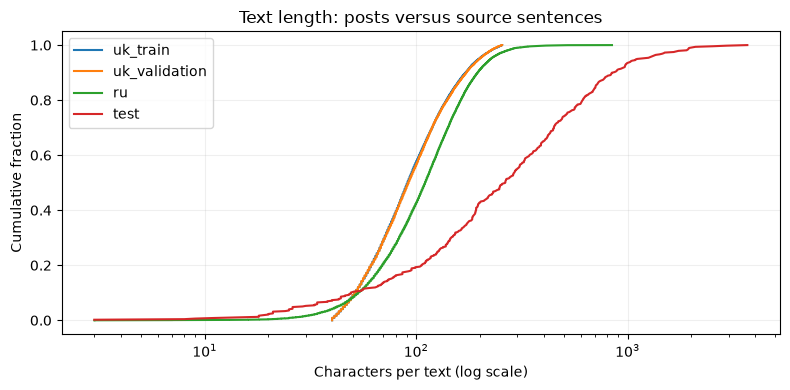

In [51]:
fig_lengths, ax = plt.subplots(figsize=(8, 4))
for name, frame in {**reference_samples, "test": test}.items():
    char_lengths = np.sort(frame.text.str.len().to_numpy())
    ax.plot(char_lengths, np.arange(1, len(char_lengths) + 1) / len(char_lengths), label=name)
ax.set(xscale="log", xlabel="Characters per text (log scale)", ylabel="Cumulative fraction", title="Text length: posts versus source sentences")
ax.legend()
ax.grid(alpha=.2)
fig_lengths.tight_layout()
plt.show()

**Результат.** Медіана test — 264 символи / 36 слів, uk train — 91 / 13, ru — 110 / 15. У test 85% дописів багаторядкові, близько 60% мають емодзі, у 32% емодзі приклеєне до слова, 18% апострофів — `ʼ`; у train цього майже немає → токенізатор має відділяти емодзі й нормалізувати апострофи без зсуву координат; навчальні речення варто склеювати в багаторядкові дописи.

### 6.2 Яких слів test немає в train?

Слова після NFKC і нижнього регістру, без лематизації. Перша таблиця — повні корпуси. Друга — частка відсутніх слів серед усіх слів test, слів із великої літери (кандидати в назви) і слів правильних відповідей sample для словника uk-вибірки, його частих слів (≥3) і uk+ru.

In [52]:
vocabulary_coverage = pd.DataFrame([result["coverage"] for result in test_scans.values()]).set_index("dataset")
display(vocabulary_coverage.round(2))
pd.DataFrame({name: pd.Series(result["unseen_words"][:25]) for name, result in test_scans.items()})

,test_word_types,unseen_test_word_types,test_token_coverage_pct
dataset,,,
uk_train,9780,1143,94.44
uk_validation,9780,4368,77.15
ru,9780,6652,51.43


,uk_train,uk_validation,ru
0,00079,00079,00079
1,00грн,00грн,00грн
2,0500200508,044,0500200508
3,063-574-50-98,0500200508,063-574-50-98
4,0631566606,063,0631566606
5,0673158715,063-574-50-98,0673158715
6,0680958123,0631566606,0680958123
7,0932626376,0673158715,0932626376
8,0963036372,0680958123,0963036372
9,10грн,0932626376,100-річної


In [53]:
# Pretrained embeddings and char layer (Lample 2016, Chiu & Nichols 2016): needed when target words are out of vocabulary.
vocab_uk = Counter(w.lower() for t in uk_sample["text"] for w in TOKEN.findall(t) if w[0].isalpha())
vocab_ru = Counter(w.lower() for t in ru["text"] for w in TOKEN.findall(t) if w[0].isalpha())
frequent = {w for w, n in vocab_uk.items() if n >= 3}
gold_words = [w.lower() for t in sample["locations"] for s in t for w in TOKEN.findall(s) if w[0].isalpha()]
test_words = [w for t in test["text"] for w in TOKEN.findall(t) if w[0].isalpha()]
names = [w for t in test["text"] for line in t.split("\n") for w in TOKEN.findall(line)[1:] if w[0].isupper()]
oov = lambda ws, v: round(float(np.mean([w.lower() not in v for w in ws])), 3)
pd.DataFrame({
    "uk vocabulary": {"all test words": oov(test_words, vocab_uk), "capitalised test words (candidates)": oov(names, vocab_uk), "gold words in sample": oov(gold_words, vocab_uk)},
    "uk, frequency >= 3": {"all test words": oov(test_words, frequent), "capitalised test words (candidates)": oov(names, frequent), "gold words in sample": oov(gold_words, frequent)},
    "uk + ru": {"all test words": oov(test_words, set(vocab_uk) | set(vocab_ru)), "capitalised test words (candidates)": oov(names, set(vocab_uk) | set(vocab_ru)), "gold words in sample": oov(gold_words, set(vocab_uk) | set(vocab_ru))},
})

,uk vocabulary,"uk, frequency >= 3",uk + ru
all test words,0.083,0.124,0.044
capitalised test words (candidates),0.157,0.225,0.096
gold words in sample,0.244,0.317,0.146


**Результат.** Із 9 780 різних слів test в uk train немає 1 143, у ru — 6 652; з урахуванням повторів uk train покриває 94,44% токенів test. Але серед слів із великої літери поза словником uk-вибірки 16%, а серед слів правильних відповідей sample — 24% → нових слів найбільше саме серед назв; потрібні претреновані ембедінги (fastText) і символьний шар.

### 6.3 Які тексти джерел найближчі до test за словами й символами?

Word TF-IDF (1–2 слова) і character TF-IDF (3–5 символів), cosine до найближчого з 20 000 рядків джерела. Словник і IDF — лише з джерела; шкали двох методів між собою не порівнюються.

In [54]:
tfidf_matches = pd.concat([tfidf_neighbors(frame, test, name, analyzer)
    for name, frame in reference_samples.items() for analyzer in ["word", "char_wb"]], ignore_index=True)
display(tfidf_matches.groupby(["dataset", "method"]).cosine.agg(["median", "mean", "max"]).round(3))
tfidf_matches.sort_values("cosine", ascending=False).groupby(["dataset", "method"], sort=False).head(2).merge(test[["text_id", "text"]], left_on="test_id", right_on="text_id").rename(columns={"text":"test_text"})

median   mean    max
dataset       method                       
ru            char_wb   0.158  0.174  0.508
              word      0.251  0.265  1.000
uk_train      char_wb   0.225  0.234  0.501
              word      0.226  0.241  0.652
uk_validation char_wb   0.207  0.220  0.531
              word      0.229  0.241  0.687

,dataset,method,test_id,cosine,source_index,source_text,text_id,test_text
0,ru,word,169,1.000000,629919,«Лара Крофт без сисек...,169,Оболонь без купюр.\n\nЖиття🫶Оболонь
1,ru,word,202,0.925446,1593584,«У Апалькова перелом.,202,"‼️ На Київщині нетверезий водій ВАЗу виїхав на зустрічну смугу і зіткнувся з автівкою ""Seat"", повідомляє поліція.\n\..."
2,uk_validation,word,150,0.686845,1001295,"Роздумуєте, що приготувати на зиму з кабачків?",150,"👂Достало лето, хотим зиму."
3,uk_train,word,321,0.652072,793312,"Протягом 31 серпня, а також 1-4 вересня в південних, східних, центральних областях збережеться надзвичайний (5 класу...",321,🥵 У Києві 30 та 31 серпня утримається надзвичайний рівень пожежної небезпеки – Укргідрометцентр
4,uk_validation,word,188,0.643443,1004800,На місці вже працюють рятувальники і чергує швидка допомога.,188,Біля цирку горить відселена будівля.\n\nНа місці вже працюють рятувальники.
5,uk_train,word,150,0.643011,907262,Птахи вилітають разом у вирій — очікуйте сувору зиму.,150,"👂Достало лето, хотим зиму."
6,uk_validation,char_wb,280,0.530997,1004042,"""Укрзалізниця"" призначила 30 додаткових поїздів до моря - Укрaїнa - TCH.",280,Укрзалізниця призначила додаткові поїзди між Васильковом та Києвом🚊\n\nГрафік👈
7,ru,char_wb,393,0.508216,6085733,Однако 9 августа Кличко получил травму спины.,393,Кличко 👉 🫶 Фіала❤️
8,uk_train,char_wb,280,0.501213,36662,Укрзалізниця призначила 10 додаткових поїздів до Дня захисника України та Покрови Пресвятої Богородиці.,280,Укрзалізниця призначила додаткові поїзди між Васильковом та Києвом🚊\n\nГрафік👈
9,uk_train,char_wb,299,0.500913,301820,"""У найближчу годину з утриманням до кінця доби 29 та протягом 30 травня грози (I рівень небезпечності, жовтий)"", - й...",299,"🌩 На Київщині очікується гроза, – Укргідрометцентр \n\nУ найближчу годину з утриманням до кінця доби 31 серпня та вн..."


**Результат.** Найближчі тексти джерел схожі слабко: медіанний word cosine — 0,23 для uk train і validation, 0,25 для ru; char — 0,23 / 0,21 / 0,16. Найближчі пари — шаблонні фрази новин (`На місці вже працюють рятувальники…`, прогнози погоди, `Укрзалізниця призначила…`); word cosine 1,0 з ru — артефакт: у короткого допису словник джерела знає лише слово `без` → спільне з train — окремі шаблонні фрази, а не тексти (повних збігів немає, 2.7).

### 6.4 Наскільки легко відрізнити речення test від речень джерела?

Character TF-IDF + логістична регресія, 3 фолди; речення одного допису — в одному фолді, однакові рядки джерела згруповані. Для порівняння — класифікатор лише за довжиною. Повна adversarial validation — у `adversarial_validation.ipynb`.

In [55]:
domain_comparison = pd.DataFrame({name: domain_auc(frame, test) for name, frame in reference_samples.items()}).T
domain_comparison.round(3)

,test_sentences,source_sentences,OOF_AUC,fold_AUC_min,fold_AUC_max,length_only_AUC
uk_train,1916.0,1916.0,0.814,0.796,0.825,0.617
uk_validation,1916.0,1916.0,0.819,0.810,0.829,0.617
ru,1916.0,1916.0,0.990,0.987,0.993,0.676


**Результат.** OOF AUC: 0,814 (uk train), 0,819 (uk validation), 0,990 (ru); лише за довжиною — 0,617 / 0,617 / 0,676 → test відрізняється від uk не тільки довжиною; uk validation не ближча до test, ніж train; ru — майже окремий домен.

### 6.5 Які назви test уже траплялися в мітках джерел?

Словники нормалізованих назв (`comparison_text`; відмінки й мови не зводимо: `Київ`, `Києві`, `Киев` — різні). Для джерел частота — кількість спанів, для GPT-test — кількість дописів. У таблиці покриття рядок — словник, який покриваємо, колонка — джерело. Потім ділимо GPT-форми test на чотири групи за очищеними мітками uk train і ru.

In [56]:
vocab_raw, vocab_clean = {}, {}
for name,counts in target_counts.items():
    merged = Counter()
    for s,n in counts.items():
        key = comparison_text(s)
        if key: merged[key] += n
    vocab_raw[name] = merged
for name,frame in sources.items():
    merged = Counter()
    for text,spans in zip(frame.text,frame.spans):
        for a,b in spans:
            key = comparison_text(text[a:b])
            if key: merged[key] += 1
    vocab_clean[name] = merged
vocab_clean["test_GPT"] = vocab_raw["test_GPT"]
vocab_sets = {name:set(counts) for name,counts in vocab_raw.items()}
vocab_table = pd.DataFrame(vocab_raw).fillna(0).astype(int).rename_axis("normalized_surface")
vocab_summary = pd.DataFrame({name:{"raw_unique_forms":len(counts),"clean_unique_forms":len(vocab_clean[name]),
    "raw_label_count":sum(counts.values()),"only_in_this_dataset":len(vocab_sets[name]-set().union(*(s for k,s in vocab_sets.items() if k!=name))),
    "raw_forms_without_letters_or_digits":sum(not any(c.isalnum() for c in s) for s in counts)} for name,counts in vocab_raw.items()}).T
display(vocab_summary)
pd.DataFrame([{"dataset":name,"surface":s,"count":count} for name,counts in target_counts.items() for s,count in counts.most_common(12)])
vocab_intersections = pd.DataFrame({right:{left:len(a&vocab_sets[right]) for left,a in vocab_sets.items()} for right in vocab_sets})
vocab_jaccard = pd.DataFrame({right:{left:len(a&vocab_sets[right])/len(a|vocab_sets[right]) if a|vocab_sets[right] else 1 for left,a in vocab_sets.items()} for right in vocab_sets})
vocab_coverage = pd.DataFrame({right:{left:100*len(a&vocab_sets[right])/len(a) if a else np.nan for left,a in vocab_sets.items()} for right in vocab_sets})
vocab_coverage.round(2)

,raw_unique_forms,clean_unique_forms,raw_label_count,only_in_this_dataset,raw_forms_without_letters_or_digits
uk_train,44511,44383,341810,40118,11
uk_validation,1421,1407,3304,300,2
ru,130797,129885,3708173,127444,14
sample_reference,30,30,32,8,0
test_GPT,481,481,768,199,0


,uk_train,uk_validation,ru,sample_reference,test_GPT
uk_train,100.00,2.49,7.47,0.05,0.60
uk_validation,77.97,100.00,14.50,0.70,6.40
ru,2.54,0.16,100.00,0.00,0.05
sample_reference,73.33,33.33,16.67,100.00,73.33
test_GPT,55.09,18.92,12.27,4.57,100.00


In [57]:
vocab_test_categories = []
for version,counts in [("raw",vocab_raw),("clean",vocab_clean)]:
    u,r = set(counts["uk_train"]),set(counts["ru"])
    for label,n in counts["test_GPT"].items():
        category = "both_uk_and_ru" if label in u and label in r else "uk_only" if label in u else "ru_only" if label in r else "neither_uk_nor_ru"
        vocab_test_categories.append({"version":version,"surface":label,"category":category,"test_prediction_count":n,
            "uk_train_count":counts["uk_train"][label],"ru_count":counts["ru"][label]})
vocab_test_categories = pd.DataFrame(vocab_test_categories)
vocab_test_summary = vocab_test_categories.groupby(["version","category"]).agg(unique_forms=("surface","size"),prediction_count=("test_prediction_count","sum"))
vocab_test_summary["unique_forms_pct"] = 100*vocab_test_summary.unique_forms/len(vocab_sets["test_GPT"])
vocab_test_summary["prediction_count_pct"] = 100*vocab_test_summary.prediction_count/sum(vocab_raw["test_GPT"].values())
display(vocab_test_summary.round(2))
display(vocab_test_categories.loc[vocab_test_categories.version.eq("clean")].sort_values("test_prediction_count",ascending=False).groupby("category",sort=False).head(15))
gpt_inventory = pd.DataFrame([{"normalized_form": comparison_text(s), "surface": s, "post_key": row.key}
                              for row in gpt_test.itertuples() for s in row.locations])
gpt_inventory = gpt_inventory.groupby("normalized_form").agg(
    posts=("post_key", "nunique"), surface_variants=("surface", lambda x: sorted(set(x))), post_keys=("post_key", lambda x: sorted(set(x)))
).sort_values("posts", ascending=False)
pd.Series({"normalized_unique_forms": len(gpt_inventory), "forms_in_one_post": int(gpt_inventory.posts.eq(1).sum()),
           "forms_in_one_post_pct": 100 * gpt_inventory.posts.eq(1).mean()}).to_frame("GPT-test").round(2)

unique_forms  prediction_count  unique_forms_pct  \
version category                                                              
clean   both_uk_and_ru               42               110              8.73   
        neither_uk_nor_ru           198               209             41.16   
        ru_only                      17                17              3.53   
        uk_only                     224               432             46.57   
raw     both_uk_and_ru               42               110              8.73   
        neither_uk_nor_ru           199               210             41.37   
        ru_only                      17                17              3.53   
        uk_only                     223               431             46.36   

                           prediction_count_pct  
version category                                 
clean   both_uk_and_ru                    14.32  
        neither_uk_nor_ru                 27.21  
        ru_only                            2.21  
        uk_only                           56.25  
raw     both_uk_and_ru                    14.32  
        neither_uk_nor_ru                 27.34  
        ru_only                            2.21  
        uk_only                           56.12

,version,surface,category,test_prediction_count,uk_train_count,ru_count
482,clean,києві,uk_only,55,6486,0
483,clean,києва,uk_only,38,4030,0
481,clean,київ,uk_only,25,2596,0
523,clean,україни,both_uk_and_ru,22,24193,13
506,clean,україні,both_uk_and_ru,18,16696,3
586,clean,столиці,uk_only,15,5,0
520,clean,київщині,uk_only,14,342,0
508,clean,шевченківському районі,uk_only,9,45,0
661,clean,київщини,uk_only,8,117,0
638,clean,україну,both_uk_and_ru,6,3992,7


,GPT-test
normalized_unique_forms,481.00
forms_in_one_post,414.00
forms_in_one_post_pct,86.07


**Результат.** Різних форм: 44 511 в uk train, 130 797 у ru, 481 у GPT-test (86% із них — лише в одному дописі). З 481 форми test 42 є і в uk, і в ru, 224 — лише в uk, 17 — лише в ru, 198 (41%) — ніде; за частотою прогнозів це 14% / 56% / 2% / 27% → чверть назв test модель не бачила як мітку; ru додає мало нових форм (`москве`, `курск`), тож більше користі дадуть контекстні ознаки й словник вулиць.

### 6.6 Скільки назв припадає на допис test?

За GPT-прогнозами: розподіл кількості назв, щільність на 100 слів, зв'язок із довжиною і bootstrap-інтервал частки порожніх (2 000 перевибірок дописів, `seed=0`).

In [58]:
fp_posts = pd.DataFrame([dict(feature_row(r.text, r.locations), post_key=r.key, text=r.text) for r in gpt_test.itertuples()])
display(pd.Series(profile(fp_posts)).to_frame("test_posts"))
fp_label_hist = fp_posts.labels.value_counts().sort_index().rename_axis("labels_per_post").to_frame("posts")
fp_label_hist["percent"] = 100*fp_label_hist.posts/len(fp_posts)
display(fp_label_hist.round(2))
fp_density = fp_posts.loc[fp_posts.words.gt(0)].copy()
fp_density["labels_per_100_words"] = 100*fp_density.labels/fp_density.words
display(fp_density.labels_per_100_words.describe(percentiles=[.25,.5,.75,.9,.95,.99]).to_frame())
fp_posts[["labels","words","chars"]].corr(method="spearman").round(3)

,test_posts
rows,477.000000
zero_labels_pct,25.576520
labels_total,768.000000
labels_per_row_mean,1.610063
labels_p50,1.000000
labels_p90,4.000000
labels_max,13.000000
words_p50,36.000000
words_p90,114.400000
kyiv_rows_pct,41.090147


,posts,percent
labels_per_post,,
0,122,25.58
1,170,35.64
2,97,20.34
3,37,7.76
4,20,4.19
5,11,2.31
6,8,1.68
7,3,0.63
8,3,0.63


,labels_per_100_words
count,476.000000
mean,5.023012
std,7.053067
min,0.000000
25%,0.000000
50%,3.200205
75%,6.250000
90%,12.019231
95%,17.207792
99%,33.333333


,labels,words,chars
labels,1.000,0.434,0.436
words,0.434,1.000,0.995
chars,0.436,0.995,1.000


In [59]:
fp_rng = np.random.default_rng(0)
fp_empty = fp_posts.labels.eq(0).to_numpy()
fp_draws = fp_rng.integers(0,len(fp_posts),size=(2000,len(fp_posts)))
fp_empty_boot = 100*fp_empty[fp_draws].mean(axis=1)
fp_empty_interval = pd.Series({"observed_empty_pct":100*fp_empty.mean(),"bootstrap_2_5_pct":np.quantile(fp_empty_boot,.025),
    "bootstrap_97_5_pct":np.quantile(fp_empty_boot,.975),"resamples":2000}).to_frame("value")
fp_empty_interval.round(2)

,value
observed_empty_pct,25.58
bootstrap_2_5_pct,21.80
bootstrap_97_5_pct,29.77
resamples,2000.00


**Результат.** 768 назв у 477 дописах, у середньому 1,61, максимум 13. Без назв — 25,58% дописів (bootstrap 21,80–29,77%), 1 назва — 35,64%, 2 — 20,34%, 3–4 — 11,95%, 5+ — 6,50%; кількість назв помірно зростає з довжиною (Spearman 0,43) → одного середнього мало: у validation потрібні і порожні дописи, і довгі з багатьма назвами.

### 6.7 Чи схожий test на train, якщо порівнювати речення з реченнями?

Ділимо дописи на речення (переноси й межі речень, захищаючи `вул.`, `м.`, `ст.`). Назва з одним входженням, що повністю в реченні, розташована однозначно; інакше речення `uncertain`. Для джерел рахуємо різні назви на рядок. TV-відстань (0 — однакові розподіли, 1 — неперетинні) — до однозначних речень test із ≥5 словами.

In [60]:
fp_sentences = pseudo_sentences(gpt_test)
fp_resolved = fp_sentences.loc[~fp_sentences.uncertain].copy()
fp_sentence_target = fp_resolved.loc[fp_resolved.words.ge(5)].copy()
fp_sentence_sensitivity = pd.DataFrame({
    "all_sentences_definite_only":profile(fp_sentences),
    "all_sentences_possible_included":profile(fp_sentences,label_col="labels_upper"),
    "resolved_sentences":profile(fp_resolved),
    "resolved_at_least_5_words":profile(fp_sentence_target),
}).T
display(fp_sentence_sensitivity.round(2))
pd.Series({"sentences":len(fp_sentences),"posts_with_sentences":fp_sentences.post_key.nunique(),
    "uncertain_sentences":int(fp_sentences.uncertain.sum()),"sentences_shorter_than_5_words":int(fp_sentences.words.lt(5).sum()),
    "fraction_all_sentences_in_resolved_5word_view_pct":100*len(fp_sentence_target)/len(fp_sentences)}).to_frame("count_or_percent")

,rows,zero_labels_pct,labels_total,labels_per_row_mean,labels_p50,labels_p90,labels_max,words_p50,words_p90,kyiv_rows_pct,street_label_rows_pct
all_sentences_definite_only,2551.0,79.62,665.0,0.26,0.0,1.0,6.0,9.0,20.0,12.54,2.23
all_sentences_possible_included,2551.0,72.25,924.0,0.36,0.0,1.0,6.0,9.0,20.0,12.54,2.23
resolved_sentences,2309.0,79.82,589.0,0.26,0.0,1.0,6.0,8.0,19.0,9.92,2.08
resolved_at_least_5_words,1694.0,75.80,528.0,0.31,0.0,1.0,6.0,11.0,21.0,10.51,2.60


,count_or_percent
sentences,2551.000000
posts_with_sentences,476.000000
uncertain_sentences,242.000000
sentences_shorter_than_5_words,649.000000
fraction_all_sentences_in_resolved_5word_view_pct,66.405331


In [61]:
fp_source_features = {name: source_features(frame) for name, frame in sources.items()}
fp_profiles = pd.DataFrame({**{name: profile(frame) for name, frame in fp_source_features.items()},
    "test_posts_GPT": profile(fp_posts), "test_sentences_resolved_5words_GPT": profile(fp_sentence_target)}).T
display(fp_profiles.T.round(2))
fp_cleaning = pd.DataFrame({name: {"raw_empty_pct": 100 * frame.labels.eq(0).mean(), "clean_empty_pct": 100 * frame.clean_labels.eq(0).mean(),
    "raw_unique_strings_total": int(frame.labels.sum()), "clean_unique_strings_total": int(frame.clean_labels.sum()),
    "rows_with_clean_LOC": int(frame.clean_labels.gt(0).sum())} for name, frame in fp_source_features.items()}).T
fp_distribution_tables = {name: distributions(frame) for name, frame in fp_source_features.items()}
fp_distribution_tables["test_posts_GPT"] = distributions(fp_posts)
fp_distribution_tables["test_sentences_resolved_5words_GPT"] = distributions(fp_sentence_target)
fp_distributions = pd.concat([table.assign(dataset=name) for name, table in fp_distribution_tables.items()], ignore_index=True)
fp_distances = distribution_distances(fp_distribution_tables, "test_sentences_resolved_5words_GPT")
fp_distances.pivot(index="dataset", columns="feature", values="total_variation").round(3)

,uk_train,uk_validation,ru,sample_reference,test_posts_GPT,test_sentences_resolved_5words_GPT
rows,1000000.00,10000.00,8028840.00,26.00,477.00,1694.00
zero_labels_pct,76.89,76.97,69.31,38.46,25.58,75.80
labels_total,338850.00,3275.00,3668443.00,32.00,768.00,528.00
labels_per_row_mean,0.34,0.33,0.46,1.23,1.61,0.31
labels_p50,0.00,0.00,0.00,1.00,1.00,0.00
labels_p90,1.00,1.00,1.00,2.00,4.00,1.00
labels_max,16.00,12.00,55.00,10.00,13.00,6.00
words_p50,13.00,13.00,15.00,29.50,36.00,11.00
words_p90,24.00,24.00,26.00,103.00,114.40,21.00
kyiv_rows_pct,2.23,2.09,0.61,46.15,41.09,10.51


feature,kyiv,labels,street,words
dataset,,,,
ru,0.099,0.065,0.022,0.231
sample_reference,0.356,0.373,0.128,0.481
test_posts_GPT,0.306,0.502,0.070,0.537
test_sentences_resolved_5words_GPT,0.000,0.000,0.000,0.000
uk_train,0.083,0.031,0.021,0.114
uk_validation,0.084,0.028,0.021,0.120


**Результат.** 2 551 речення в 476 дописах, 242 з них невизначені. Серед 1 694 однозначних речень із ≥5 словами 75,80% без назв і 0,312 назви на речення — майже як в uk validation (76,97% / 0,328; TV за кількістю назв 0,028). Але Київ згадується в 10,51% речень test проти 2,09% у validation, вуличні мітки — 2,60% проти 0,53% → щільністю міток train схожий на test, тематикою — ні; validation варто збагатити київськими й вуличними прикладами.

### 6.8 Як частка дописів без назв залежить від довжини?

In [62]:
fp_joint_rows = []
for name,frame in {"test_posts_GPT":fp_posts,"test_sentences_resolved_5words_GPT":fp_sentence_target}.items():
    for key,count in strata(frame).value_counts().items():
        fp_joint_rows.append({"view":name,"label_bin":key[0],"word_bin":key[1],"kyiv":key[2],"street":key[3],"rows":count,"percent":100*count/len(frame)})
fp_joint = pd.DataFrame(fp_joint_rows)
fp_conditional = fp_posts.assign(word_bin=pd.cut(fp_posts.words,[-1,15,30,60,120,np.inf],labels=["0-15","16-30","31-60","61-120","121+"]),empty=fp_posts.labels.eq(0))
fp_conditional = fp_conditional.groupby("word_bin",observed=False).agg(posts=("labels","size"),empty_pct=("empty",lambda x:100*x.mean()),labels_mean=("labels","mean"))
fp_conditional.round(2)

,posts,empty_pct,labels_mean
word_bin,,,
0-15,105,42.86,0.70
16-30,114,22.81,1.12
31-60,117,23.93,1.77
61-120,96,16.67,2.12
121+,45,15.56,3.47


**Результат.** Серед дописів до 15 слів без назв 42,86%, серед дописів понад 120 слів — 15,56% (у середньому 0,70 проти 3,47 назви) → довжина й нульовий клас пов'язані; при формуванні validation враховуємо їх разом.

### 6.9 Якою мовою написані test і джерела?

[Lingua](https://github.com/pemistahl/lingua-py) вибирає з uk, ru, en, pl, be; `uncertain` — якщо впевненість <0,8 або відрив від другої мови <0,2. Test — цілі дописи й однозначні речення з ≥5 словами (6.7); джерела — контрольні вибірки по 20 000 рядків.

In [63]:
language_summary = []
for name, frame in {"test": test, **reference_samples, "test_sentences_resolved_5words": fp_sentence_target}.items():
    detected = language_profile(frame.text)
    reported = detected.language.mask(detected.uncertain, "uncertain")
    for language, count in reported.value_counts().items():
        language_summary.append({"dataset": name, "language": language, "rows_checked": len(frame), "rows": count, "percent": round(100 * count / len(frame), 2)})
language_summary = pd.DataFrame(language_summary)
language_summary.pivot(index="language", columns="dataset", values="percent").fillna(0)

dataset,ru,test,test_sentences_resolved_5words,uk_train,uk_validation
language,,,,,
be,0.00,0.00,0.00,0.01,0.01
en,0.32,0.63,0.59,0.02,0.01
pl,0.01,0.21,0.18,0.00,0.00
ru,98.96,7.97,5.96,0.00,0.00
uk,0.00,89.73,89.08,99.75,99.77
uncertain,0.71,1.47,4.19,0.21,0.21


**Результат.** Дописи test: 89,73% uk, 7,97% ru, 3 en, 1 pl і 7 невпевнених; серед речень — 89,08% uk і 5,96% ru. Контрольні uk train — 99,75% uk, ru — 98,96% ru → російською лише 6–8% test, тож ru-дані додаємо обмежено.

### 6.10 Скільки дописів test мають підпис каналу?

Підпис — короткий рядок (<80 символів) із закликом підписатися чи надіслати новину або нікнейм `@...`.

In [64]:
FOOTER_RE = re.compile(r"(?i)підписат(ись|ися)|подписаться|надіслати новину|запропонувати новину|пряма трансляція|життя🫶оболонь|^@\w+$")


def is_footer(line):
    return len(line) < 80 and bool(FOOTER_RE.search(line))


footers = Counter(line.strip() for t in test["text"] for line in set(t.split("\n")) if is_footer(line.strip()))
display(pd.Series({
    "дописів із підписом каналу": int(test["text"].map(lambda t: any(is_footer(l.strip()) for l in t.split("\n"))).sum()),
    "text_id строго зростає": bool(test["text_id"].is_monotonic_increasing),
}).to_frame("test"))
footers.most_common(10)

,test
дописів із підписом каналу,142
text_id строго зростає,True


[('Підписатись на Дарниця Livе', 24),
 ('👉👉Запропонувати новину👈👈', 24),
 ('Хуйовий Київ | Надіслати новину', 20),
 ('Київ — пряма трансляція 👈', 18),
 ('🔷\xa0Підписатися на Telegram\xa0| Instagram\xa0| Facebook\xa0| TikTok', 18),
 ('Життя🫶Оболонь', 17),
 ('Надіслати новину', 17),
 ('Підписатися\xa0\xa0\xa0 |\xa0\xa0\xa0 Запропонувати новину', 13),
 ('@lossolomas_kyiv', 7),
 ('🔷 Підписатися на Telegram | Instagram | Facebook | TikTok', 6)]

**Результат.** 142 із 477 дописів (30%) мають підпис каналу; найчастіші — `Запропонувати новину`, `Підписатись на Дарниця Livе`. Назви в підписах (`Оболонь`, `Дарниця`) розмітник, імовірно, не рахує → підписи прибираємо перед прогнозом (8.3).

## 7. Послідовності для RNN

### 7.1 Яка довжина текстів у токенах і який `max_len` потрібен?

Токени — регулярний вираз `TOKEN` із хелперів; uk — 200 000 випадкових рядків.

In [65]:
length = lambda df: df["text"].map(lambda t: len(TOKEN.findall(t)))
lengths = {"uk": length(uk_sample), "ru": length(ru), "test": length(test), "labeling_sample": length(sample)}
display(pd.DataFrame({k: v.describe(percentiles=[0.5, 0.9, 0.99])[["50%", "90%", "99%", "max"]] for k, v in lengths.items()}).round(0).astype(int))
pd.Series({f"max_len {c}": round(float((lengths["test"] <= c).mean()), 3) for c in [128, 256, 512, 700]}, name="test posts fully covered").to_frame()

,uk,ru,test,labeling_sample
50%,16,18,46,36
90%,29,32,148,144
99%,41,50,361,184
max,73,251,599,187


,test posts fully covered
max_len 128,0.862
max_len 256,0.973
max_len 512,0.998
max_len 700,1.000


**Результат.** Медіана — 16 токенів в uk і 46 у test, p99 — 41 проти 361, максимум у test — 599, а в uk лише 73. `max_len` 512 повністю вміщує 99,8% дописів test, 256 — 97,3%, 128 — 86,2% → для цілого допису достатньо 512 (або 256 з вікнами, 7.3); довгих послідовностей train не містить, тож без склеювання речень модель їх не побачить.

### 7.2 Скільки спанів губиться при перетворенні координати → BIO → координати?

Oracle-перевірка без моделі: відомі спани переводимо в теги на токенізаторі `TOKEN` і назад. Перша таблиця — F1-стеля для BIO та IO (IO зливає сусідні назви) на 200 000 рядках uk. Друга — частка точно відновлених очищених спанів для повних текстів, префіксів і вікон: uk train і ru — по 5 000 рядків, uk validation і sample — повністю. Частково обрізана назва не вважається збереженою.

In [66]:
# Ceiling: gold spans -> tokens -> tags -> strings. Everything lost here is lost before any model runs.
def ceiling(df, span_col, merge_adjacent=False):
    gold, pred, bad, total = [], [], 0, 0
    for text, spans in zip(df["text"], df[span_col]):
        offsets = tokenize(text)
        tags, misaligned = spans_to_bio(offsets, spans)
        bad, total = bad + misaligned, total + len(spans)
        gold.append([text[a:b] for a, b in spans])
        pred.append(bio_to_strings(text, offsets, tags, merge_adjacent))
    return {"F1 ceiling": comp_metric(gold, pred), "misaligned spans": round(bad / max(total, 1), 4)}


pd.DataFrame({
    "raw markers, BIO": ceiling(uk_sample, "loc_markers"),
    "raw markers, IO": ceiling(uk_sample, "loc_markers", merge_adjacent=True),
    "cleaned markers, BIO": ceiling(uk_sample, "spans"),
    "cleaned markers, IO": ceiling(uk_sample, "spans", merge_adjacent=True),
    "labeling_sample, BIO": ceiling(sample, "spans"),
})

,"raw markers, BIO","raw markers, IO","cleaned markers, BIO","cleaned markers, IO","labeling_sample, BIO"
F1 ceiling,0.995863,0.965779,0.995817,0.978639,1.0000
misaligned spans,0.004900,0.004900,0.004300,0.004300,0.0312


In [67]:
recovery_settings = [("full",None,None),("prefix_32",32,None),("prefix_64",64,None),("prefix_128",128,None),
    ("prefix_256",256,None),("prefix_512",512,None),("windows_64_stride_32",64,32),("windows_128_stride_64",128,64)]
recovery_frames = {"uk_train_5000":uk.loc[uk.is_valid.eq(0)].sample(5000,random_state=0),
    "ru_5000":ru.sample(5000,random_state=0),"uk_validation":uk.loc[uk.is_valid.eq(1)],"sample":sample}
recovery_tables = []
for name,frame in recovery_frames.items():
    for col in ["loc_markers","spans"]:
        table = span_recovery(frame,tokenize,spans_to_bio,recovery_settings,span_col=col)
        recovery_tables.append(table.rename_axis("input_policy").reset_index().assign(dataset=name,target=col))
recovery_results = pd.concat(recovery_tables,ignore_index=True)
display(recovery_results.loc[recovery_results.target.eq("spans")].pivot(index="input_policy",columns="dataset",values="oracle_span_recall_pct").round(2))
recovery_results.loc[recovery_results.input_policy.eq("full"),["dataset","target","gold_spans","not_representable_by_BIO","full_sequence_extra_spans","oracle_span_recall_pct"]]

dataset,ru_5000,sample,uk_train_5000,uk_validation
input_policy,,,,
full,99.75,96.88,99.49,99.54
prefix_128,99.75,93.75,99.49,99.54
prefix_256,99.75,96.88,99.49,99.54
prefix_32,95.31,68.75,97.41,97.28
prefix_512,99.75,96.88,99.49,99.54
prefix_64,99.66,93.75,99.49,99.54
windows_128_stride_64,99.75,96.88,99.49,99.54
windows_64_stride_32,99.75,96.88,99.49,99.54


,dataset,target,gold_spans,not_representable_by_BIO,full_sequence_extra_spans,oracle_span_recall_pct
0,uk_train_5000,loc_markers,1786,12,12,99.328108
8,uk_train_5000,spans,1773,9,9,99.492386
16,ru_5000,loc_markers,2387,6,6,99.748638
24,ru_5000,spans,2386,6,6,99.748533
32,uk_validation,loc_markers,3304,18,18,99.455206
40,uk_validation,spans,3273,15,15,99.541705
48,sample,loc_markers,32,1,1,96.875000
56,sample,spans,32,1,1,96.875000


**Результат.** F1-стеля на очищених мітках: BIO — 0,996, IO — 0,979 (IO зливає суміжні назви) → беремо BIO. Точно відновлюються 99,49% спанів uk train, 99,75% ru, 99,54% uk validation і 31 з 32 sample; решта — спани з межею посеред токена (0,4%). У validation навіть префікс 64 нічого не губить, а sample вже при 64–128 токенах втрачає назву → короткі речення validation не показують ризику обрізання довгих дописів (7.3).

### 7.3 Скільки назв test опиняються за межею обрізання?

Беремо GPT-прогнози, що трапляються в дописі рівно один раз, і рахуємо ту саму oracle-відновлюваність для префіксів і вікон. Друга таблиця — назви, що лежать далі 64-го токена.

In [68]:
recovery_test_rows, recovery_late_examples = [], []
recovery_ambiguous = 0
for row in gpt_test.itertuples():
    spans = []
    offsets = tokenize(row.text)
    cutoff = offsets[63][1] if len(offsets)>=64 else len(row.text)
    for label in row.locations:
        hits = [(m.start(),m.end()) for m in re.finditer(re.escape(label),row.text)]
        if len(hits)!=1:
            recovery_ambiguous += 1
            continue
        spans.append(hits[0])
        if hits[0][1]>cutoff:
            recovery_late_examples.append({"key":row.key,"surface":label,"start":hits[0][0],"end":hits[0][1],"prefix64_end":cutoff})
    recovery_test_rows.append({"text":row.text,"spans":sorted(spans)})
recovery_test = pd.DataFrame(recovery_test_rows)
recovery_test_results = span_recovery(recovery_test,tokenize,spans_to_bio,recovery_settings)
display(recovery_test_results.assign(ambiguous_predictions_excluded=recovery_ambiguous).round(2))
pd.DataFrame(recovery_late_examples).head(12)

,texts,gold_spans,not_representable_by_BIO,full_sequence_extra_spans,recoverable_spans,lost_to_length_or_windows,oracle_span_recall_pct,ambiguous_predictions_excluded
full,477,674,3,1,671,0,99.55,94
prefix_32,477,674,3,1,430,241,63.80,94
prefix_64,477,674,3,1,547,124,81.16,94
prefix_128,477,674,3,1,640,31,94.96,94
prefix_256,477,674,3,1,669,2,99.26,94
prefix_512,477,674,3,1,671,0,99.55,94
windows_64_stride_32,477,674,3,1,671,0,99.55,94
windows_128_stride_64,477,674,3,1,671,0,99.55,94


,key,surface,start,end,prefix64_end
0,test:24,Харківщини,564,574,380
1,test:44,Києва,274,279,273
2,test:49,міста Києва,758,769,423
3,test:56,Луганських,393,403,392
4,test:56,Донецьких областей,407,425,392
5,test:56,росії,681,686,392
6,test:56,Україні,825,832,392
7,test:56,закордоном,836,846,392
8,test:68,Києві,1510,1515,377
9,test:70,Хрещатику 36,481,493,319


**Результат.** З 674 однозначних прогнозів повний BIO відновлює 671 (94 неоднозначні виключено); префікс 64 токени — лише 81,16%, 128 — 94,96%, 256 — 99,26%; вікна 64 із кроком 32 покривають усі 671 → потрібен `max_len` ≥256 або ковзні вікна зі злиттям прогнозів.

### 7.4 Скільки в розмітці багатотокенних і суміжних сутностей?

Суміжні — дві назви, між якими лише пробіл або `,` / `і` / `та`.

In [69]:
# Multi-word and adjacent entities (CRF / BIO constraints, Lample 2016): how much structure is there to model?
def structure(df):
    c = Counter()
    for text, spans in zip(df["text"], df["spans"]):
        spans = sorted(spans)
        for (a1, b1), (a2, b2) in zip(spans, spans[1:]):
            gap = text[b1:a2]
            c["adjacent pairs, gap is whitespace"] += gap.strip() == ""
            c["adjacent pairs, gap is , or и/і/та"] += gap.strip().lower() in {",", "і", "й", "та", "и"}
        c["entities"] += len(spans)
        c["multi-token entities"] += sum(len(TOKEN.findall(text[a:b])) > 1 for a, b in spans)
    return c


pd.DataFrame({"uk": structure(uk_sample), "ru": structure(ru), "labeling_sample": structure(sample)}).fillna(0).astype(int)

,uk,ru,labeling_sample
entities,67799,3706582,32
multi-token entities,11676,576439,9
"adjacent pairs, gap is whitespace",808,44917,0
"adjacent pairs, gap is , or и/і/та",5130,301483,2


**Результат.** Багатотокенних сутностей 17% в uk, 16% у ru і 28% у sample. Суміжних пар, розділених лише пробілом, — 1,2% сутностей uk і ru, через кому чи `і`/`та` — 7,6% / 8,1% → I-тег потрібен (IO злив би такі пари, 7.2); CRF чи заборона переходу `O → I` можуть допомогти з довгими назвами.

## 8. Сигнали для моделі: ідеї зі статей і змагань

Для кожної ідеї шукаємо в даних підставу за чи проти. Моделі не навчаємо.

### 8.1 Наскільки регістр і сусідні слова вказують на локацію?

200 000 рядків uk, очищені мітки. P(LOC) для форм регістру та слів ліворуч і праворуч від назви; `lift` — у скільки разів це вище за базову частку LOC-токенів.

In [70]:
# Which token-level signals predict LOC? Case, left and right context, on cleaned uk markers.
stats = {"case": Counter(), "left": Counter(), "right": Counter()}
loc_tok, other_tok = 0, 0
for text, spans in zip(uk_sample["text"], uk_sample["spans"]):
    offsets = tokenize(text)
    toks = [text[a:b] for a, b in offsets]
    tags, _ = spans_to_bio(offsets, spans)
    for i, w in enumerate(toks):
        if not w[0].isalpha():
            continue
        is_loc = tags[i] != "O"
        loc_tok, other_tok = loc_tok + is_loc, other_tok + (not is_loc)
        case = "ALLCAPS" if w.isupper() and len(w) > 1 else "Capitalized, sentence start" if w[0].isupper() and i == 0 else "Capitalized, mid-sentence" if w[0].isupper() else "lowercase"
        stats["case"][(case, is_loc)] += 1
        if tags[i] == "B":
            stats["left"][(toks[i - 1].lower() if i else "<s>", True)] += 1
        elif not is_loc:
            stats["left"][(toks[i - 1].lower() if i else "<s>", False)] += 1
        if is_loc and (i + 1 == len(tags) or tags[i + 1] != "I"):
            stats["right"][(toks[i + 1].lower() if i + 1 < len(toks) else "</s>", True)] += 1
        elif not is_loc:
            stats["right"][(toks[i + 1].lower() if i + 1 < len(toks) else "</s>", False)] += 1

base_rate = loc_tok / (loc_tok + other_tok)


def cue_table(counts, min_count=300, top=8):
    keys = {k for k, _ in counts}
    rows = [(k, counts[(k, True)], counts[(k, True)] / (counts[(k, True)] + counts[(k, False)])) for k in keys if counts[(k, True)] >= min_count]
    return pd.DataFrame(sorted(rows, key=lambda r: -r[2])[:top], columns=["cue", "LOC count", "P(LOC)"]).assign(lift=lambda d: (d["P(LOC)"] / base_rate).round(1)).round(3)


print("base rate of LOC tokens:", round(base_rate, 4))
display(cue_table(stats["case"], min_count=1))
display(cue_table(stats["left"]))
cue_table(stats["right"])

base rate of LOC tokens: 0.0287


,cue,LOC count,P(LOC),lift
0,"Capitalized, mid-sentence",68812,0.282,9.8
1,ALLCAPS,3578,0.119,4.1
2,"Capitalized, sentence start",987,0.005,0.2
3,lowercase,8041,0.003,0.1


,cue,LOC count,P(LOC),lift
0,місті,369,0.591,20.6
1,новини,326,0.556,19.4
2,території,385,0.413,14.4
3,міста,300,0.377,13.1
4,президент,541,0.326,11.4
5,президента,373,0.260,9.0
6,в,9800,0.204,7.1
7,проти,346,0.200,6.9


,cue,LOC count,P(LOC),lift
0,),682,0.118,4.1
1,(,737,0.111,3.9
2,та,2607,0.104,3.6
3,-,2505,0.078,2.7
4,—,422,0.074,2.6
5,–,746,0.073,2.5
6,.,12073,0.066,2.3
7,:,505,0.063,2.2


**Результат.** Базова частка LOC-токенів — 2,87%. Слово з великої літери посеред речення — LOC у 28% випадків (lift 9,8), з малої — 0,3%, перше слово речення — 0,5%. Лівий контекст сильніший (`місті` ×20,6, `в` ×7,1) за правий (дужки, `та`, тире — ×2,5–4), але сигнал є з обох боків → двонаправлена RNN і ознака регістру виправдані.

### 8.2 Чи вказує закінчення слова на локацію?

Серед слів із великої літери (довших за 4 літери, не на початку речення) рахуємо P(LOC) за трьома останніми літерами. Окремо — найчастіші форми `Київ` у мітках uk.

In [71]:
# Char layer (Ma & Hovy 2016, Yang 2018): do word endings identify a place among capitalised words?
capitalised = Counter()
for text, spans in zip(uk_sample["text"], uk_sample["spans"]):
    offsets = tokenize(text)
    tags, _ = spans_to_bio(offsets, spans)
    for i, (a, b) in enumerate(offsets[1:], 1):
        w = text[a:b]
        if w[0].isupper() and w[1:].islower() and len(w) > 4:
            capitalised[(w[-3:].lower(), tags[i] != "O")] += 1
ending_base = sum(v for (k, loc), v in capitalised.items() if loc) / sum(capitalised.values())
endings = {k for k, _ in capitalised}
rows = [(k, capitalised[(k, True)] + capitalised[(k, False)], capitalised[(k, True)] / (capitalised[(k, True)] + capitalised[(k, False)])) for k in endings if capitalised[(k, True)] + capitalised[(k, False)] >= 400]
table = pd.DataFrame(rows, columns=["last 3 letters", "words", "P(LOC)"]).sort_values("P(LOC)", ascending=False).round(3)
print(f"base rate among capitalised words: {ending_base:.3f}")
forms = Counter(t[a:b] for t, s in zip(uk["text"], uk["spans"]) for a, b in s if re.match(r"Ки[їє]в|Києв", t[a:b]) and " " not in t[a:b])
display(pd.concat([table.head(10), table.tail(5)]))
forms.most_common(8)

base rate among capitalised words: 0.315


,last 3 letters,words,P(LOC)
71,асі,680,0.990
56,їні,3373,0.982
36,їну,789,0.980
69,єві,1392,0.979
14,ьщі,503,0.948
2,ині,1653,0.946
47,иму,758,0.946
74,вці,430,0.923
8,усі,412,0.891
41,нії,1220,0.872


[('Києві', 6544),
 ('Києва', 4062),
 ('Київ', 2630),
 ('Києвом', 548),
 ('Київщині', 344),
 ('Києву', 191),
 ('Київщини', 118),
 ('Києво', 91)]

**Результат.** Базова частка LOC серед таких слів — 31,5%, а закінчення `-асі`, `-їні`, `-їну`, `-єві` дають P(LOC) 0,98–0,99. Сам `Київ` має щонайменше 8 частих форм (`Києві` 6 544, `Києва` 4 062, `Київ` 2 630, …) → символьний шар допоможе з відмінками й новими назвами.

### 8.3 Скільки дає простий словник локацій без контексту?

Словник — назви, розмічені в uk ≥5 разів; шукаємо найдовший збіг, що починається з великої літери. Офіційна метрика на чистій validation (`valid_mask`) і на sample, також без підписів каналів (6.10) і без `Україна`.

In [72]:
# Gazetteers (Chiu & Nichols; warning from Coleridge): how far does a context-free lookup of train locations go?
loc_strings = Counter(tuple(w.lower() for w in TOKEN.findall(t[a:b])) for t, s in zip(uk["text"], uk["spans"]) for a, b in s)
lexicon = {k for k, n in loc_strings.items() if n >= 5 and k}
max_words = max(map(len, lexicon))


def lookup(text, exclude_ukraine=False):
    offsets, out, i = tokenize(text), [], 0
    words = [text[a:b] for a, b in offsets]
    while i < len(words):
        for n in range(min(max_words, len(words) - i), 0, -1):
            key = tuple(w.lower() for w in words[i:i + n])
            if key in lexicon and words[i][:1].isupper():
                out.append(text[offsets[i][0]:offsets[i + n - 1][1]])
                i += n
                break
        else:
            i += 1
    return [s for s in out if not (exclude_ukraine and re.fullmatch(r"(?i)україн\w*|украин\w*", s))]


def score(y_true, y_pred):
    tp = fp = fn = 0
    for t, p in zip(y_true, y_pred):
        t, p = {hard_processing(s) for s in t}, {hard_processing(s) for s in p}
        tp, fp, fn = tp + len(t & p), fp + len(p - t), fn + len(t - p)
    return {"F1": comp_metric(y_true, y_pred), "TP": tp, "FP": fp, "FN": fn}


val_df = uk[valid_mask]
val_gold = [[t[a:b] for a, b in s] for t, s in zip(val_df["text"], val_df["spans"])]
kept_lines = lambda t: "\n".join(l for l in t.split("\n") if not is_footer(l.strip()))
y_true = sample["locations"].tolist()
print("lexicon entries:", len(lexicon))
pd.DataFrame({
    "uk is_valid": score(val_gold, [lookup(t) for t in val_df["text"]]),
    "sample": score(y_true, [lookup(t) for t in sample["text"]]),
    "sample, no footers": score(y_true, [lookup(kept_lines(t)) for t in sample["text"]]),
    "sample, no footers, no Україна": score(y_true, [lookup(kept_lines(t), True) for t in sample["text"]]),
}).T

lexicon entries: 4802


,F1,TP,FP,FN
uk is_valid,0.668123,2599.0,2042.0,540.0
sample,0.395062,16.0,33.0,16.0
"sample, no footers",0.426667,16.0,27.0,16.0
"sample, no footers, no Україна",0.450704,16.0,23.0,16.0


**Результат.** Словник із 4 802 назв дає F1 0,67 на validation і 0,40 на sample (16 TP, 33 FP); прибирання підписів каналів знімає 6 із 33 FP, а виключення `Україна` — ще 4 → як самостійне правило словник слабкий, але годиться як додаткова ознака; прибирання підписів варто перевірити в експерименті.

### 8.4 Чи часто назва повторюється в одному тексті?

Якщо часто, прогнози для однакових рядків у тексті можна агрегувати (рішення 1-го місця PII).

In [73]:
# Same-string aggregation (PII 1st): how many gold strings have several occurrences, so one confident hit is enough?
repeats = [len(re.findall(rf"(?<!\w){re.escape(s)}(?!\w)", t)) for t, gold in zip(sample["text"], sample["locations"]) for s in set(gold)]
repeated_names = []
for t in test["text"]:
    caps = Counter(w for line in t.split("\n") for w in TOKEN.findall(line)[1:] if w[0].isupper() and w[1:].islower() and len(w) > 3)
    repeated_names += list(caps.values())
pd.Series({
    "sample: gold strings": len(repeats),
    "sample: gold strings occurring more than once": int(sum(r > 1 for r in repeats)),
    "test: distinct capitalised words in a post": len(repeated_names),
    "test: of these, repeated in the same post": int(sum(r > 1 for r in repeated_names)),
})

sample: gold strings                               32
sample: gold strings occurring more than once       2
test: distinct capitalised words in a post       2738
test: of these, repeated in the same post         211
dtype: int64

**Результат.** Лише 2 з 32 назв sample трапляються в тексті більше одного разу; у test повторюються 211 з 2 738 (8%) слів із великої літери → агрегація однакових рядків — низький пріоритет.

### 8.5 Що дані кажуть про ідеї з літератури

| Ідея | Джерело | Що показують дані | Висновок |
|---|---|---|---|
| Претреновані fastText | Lample 2016, Chiu & Nichols 2016 | 24% слів відповідей sample і 16% слів test із великої літери немає у словнику uk (6.2) | пробувати першим |
| Символьний шар | Ma & Hovy 2016, Yang 2018 | закінчення `-їні`, `-єві`, `-асі` дають P(LOC) 0,98–0,99; `Київ` має 8+ частих форм (8.2) | варто пробувати |
| Ознака регістру, копії train у нижньому регістрі | Chiu & Nichols, Mayhew 2019 | регістр посеред речення — сильний сигнал (8.1), але 4 з 32 назв sample починаються з малої літери | варто пробувати |
| Двонаправлена RNN | Ma & Hovy 2016 | сигнал є і ліворуч, і праворуч (8.1) | варто пробувати |
| CRF або обмеження BIO | Lample 2016 | багатотокенних сутностей 17% в uk і 28% у sample (7.4) | перевірити |
| Більше вулиць у train | Dai & Adel 2020, Coleridge 1st | вулиці 1,6% в uk проти 15,6% у sample; у ru протилежна межа (4.4, 4.6) | варто, головний розрив |
| Словник локацій як правило | Chiu & Nichols, застереження Coleridge | 0,67 на silver і 0,40 на sample (16 TP, 33 FP) (8.3) | лише як ознака |
| Злиття однакових рядків у тексті | PII 1st | повторюються 2 з 32 назв sample і 8% слів із великої літери test (8.4) | низький пріоритет |
| Прибирання підписів каналів | PII 1st, постобробка | 142 дописи test, мінус 6 з 33 FP на sample (6.10, 8.3) | варто пробувати |
| Partial CRF для шумних міток | Mayhew 2019 | `Київ` не розмічений лише в 1,1% випадків, `Україна` — у 9,1%: це різниця політики, а не випадковий шум (4.9) | низький пріоритет |
| Псевдорозмітка | Toxic 1st, Quora 1st | у test лише 477 дописів, і підстав мало | не пріоритет |

У sample лише 32 згадки, тож його числа орієнтовні, а не вимір.

## 9. Групи, час і схема валідації

- **Часу немає:** у даних немає дат, `text_id` лише зростає (6.10) → поділ за часом неможливий.
- **Групи:** `doc_id` у ru (739 190 документів, медіана 10 речень, 2.5), нормалізовані повтори в uk (2.2), підписи каналів (142 дописи, 6.10) і 9 пар майже-копій у test (2.8).

**Пропонована валідація**
1. Однакові фолди для всіх експериментів: групування за `norm` (uk) і `doc_id` (ru) плюс окрема перевірка однакових речень ru між фолдами (2.5). Silver-фолди показують, чи модель взагалі вчиться.
2. `labeling_sample` замалий для підбору порогів (5.3) — використовуємо його як санітарну перевірку на кількох seed.
3. Рішення щодо політики (вулиці, `Україна`, підписи) sample не вирішить — потрібні сабміти. Test вручну не розмічаємо.

Кореляція CV з лідербордом очікувано слабка через зсув домену (6.4) і різну політику розмітки (4.10). Для змін токенізації й очищення вона має бути вищою, для всього, що залежить від частки вулиць, — нижчою.

## 10. Висновки: що беремо в експерименти

**Підготовка даних (обов'язково)**

| Факт | Де | Дія |
|---|---|---|
| Дефекти меж у до 1,6% спанів; `clean_spans` нічого не губить | 1.4, 1.5 | BIO будуємо з очищених `spans` |
| 79 рядків validation повторюють train | 2.6 | прибрати з validation (`valid_mask`) |
| 44 групи uk і 4 786 груп ru мають різні мітки для того самого тексту | 2.3, 2.4 | дедуплікувати лише узгоджені копії, конфліктні відкласти |
| 6,52% ru — повтори шаблонів, `doc_id` не розділяє їх | 2.4, 2.5 | дедуплікувати ru і після поділу прибрати з train речення validation |
| Підпис TCH у 9 249 рядках uk поряд із корисними мітками | 1.6 | вирізати підпис, а не весь рядок |
| Метрика не прибирає кому й ламає латиницю | 5.1, 5.2 | рядок відповіді вирізати з тексту, обрізати крайову пунктуацію, викидати порожні після нормалізації |
| Емодзі приклеєні до слів, `ʼ` у 18% апострофів test | 6.1 | токенізатор відділяє емодзі й нормалізує апострофи без зсуву координат |
| Префікс 64 токени втрачає 19% назв test | 7.3 | `max_len` ≥256 або ковзні вікна |

**Варто пробувати — від більшої очікуваної користі до меншої**
1. Претреновані fastText uk + ru (6.2, 8.5).
2. Більше вулиць, районів і POI в train: спершу наявні речення, потім заміна згадок за зовнішнім списком вулиць (4.4).
3. Символьний шар і ознака регістру, навчання на оригінальному й нижньому регістрі (8.1, 8.2).
4. Входи, схожі на дописи: склеювання речень у багаторядкові тексти, прогноз по рядках (6.1).
5. Прибирання підписів каналів перед прогнозом (6.10, 8.3).
6. CRF або заборона переходу `O → I` (7.4).
7. Рішення щодо `Україна` — сабмітом, бо в sample лише 4 згадки (4.9).
8. Ансамбль за seed і ембедінгами — наприкінці.

**Додаткові метрики в експериментах:** token F1 для B/I, точний span F1 (seqeval), recall за типом сутності (місто, вулиця, район), частка FP на текстах без локацій, recall на назвах, яких немає в train, `overlap_f1` (5.2).

**Обмеження ru.** Російською лише 6–8% test (6.9), а межа вулиць у ru протилежна uk (4.6) → ru додаємо обмежено й перевіряємо окремо.

**Правило змагання.** «Manual labeling of test set is strictly forbidden!» Інших обмежень на архітектуру чи зовнішні дані тут не виводимо.

**Орієнтир.** У 2025 році бейзлайн RNN мав 0,562, BERT — 0,648, найкращі команди — 0,65–0,66.

## 11. Експорт таблиць у `results/`

In [74]:
analysis_dir = RESULTS / "test_analysis"
fingerprint_dir = analysis_dir / "test_fingerprint"
vocab_dir = analysis_dir / "label_vocabularies"
preflight_dir = RESULTS / "preflight"
for directory in [analysis_dir, fingerprint_dir, vocab_dir, preflight_dir]:
    directory.mkdir(parents=True, exist_ok=True)

exports = {
    # target (section 4)
    analysis_dir / "target_density.csv": target_density, analysis_dir / "target_type_patterns.csv": target_types,
    analysis_dir / "target_form.csv": target_form, analysis_dir / "target_unique_form.csv": target_unique_form,
    analysis_dir / "target_boundaries.csv": target_boundary, analysis_dir / "target_context.csv": target_context,
    analysis_dir / "target_context_examples.csv": target_context_examples, analysis_dir / "target_mention_rates.csv": target_mention_rates,
    analysis_dir / "label_form_profile.csv": target_form.loc[["uk_train", "ru", "sample_reference", "test_GPT"]],
    analysis_dir / "unique_label_form_profile.csv": target_unique_form.loc[["uk_train", "ru", "sample_reference", "test_GPT"]],
    analysis_dir / "label_boundary_policy.csv": target_boundary.loc[["uk_train", "ru", "test_GPT"]],
    analysis_dir / "same_name_label_variants.csv": label_variants,
    analysis_dir / "controlled_label_policy_differences.csv": controlled_differences,
    analysis_dir / "GPT_reference_agreement.csv": agreement_summary, analysis_dir / "GPT_reference_differences.csv": agreement_rows,
    # test versus sources (sections 2 and 6)
    analysis_dir / "structure.csv": structure_comparison, analysis_dir / "exact_overlap.csv": exact_test_overlap,
    analysis_dir / "vocabulary.csv": vocabulary_coverage, analysis_dir / "language.csv": language_summary.loc[language_summary.dataset.ne("test_sentences_resolved_5words")],
    analysis_dir / "tfidf_neighbors.csv": tfidf_matches, analysis_dir / "domain_auc.csv": domain_comparison,
    analysis_dir / "test_near_pairs.csv": internal_test_pairs,
    analysis_dir / "GPT_LOC_coverage.csv": vocab_test_summary,
    # test profile (section 6)
    fingerprint_dir / "posts.csv": fp_posts, fingerprint_dir / "sentences.csv": fp_sentences,
    fingerprint_dir / "post_label_histogram.csv": fp_label_hist, fingerprint_dir / "empty_bootstrap.csv": fp_empty_interval,
    fingerprint_dir / "sentence_sensitivity.csv": fp_sentence_sensitivity, fingerprint_dir / "source_comparison.csv": fp_profiles,
    fingerprint_dir / "cleaning_sensitivity.csv": fp_cleaning, fingerprint_dir / "distributions.csv": fp_distributions,
    fingerprint_dir / "distribution_distances.csv": fp_distances, fingerprint_dir / "joint_test_profile.csv": fp_joint,
    fingerprint_dir / "empty_by_length.csv": fp_conditional,
    fingerprint_dir / "language.csv": language_summary.loc[language_summary.dataset.str.startswith("test")],
    fingerprint_dir / "GPT_zero_class_control.csv": fp_control_summary, fingerprint_dir / "entity_inventory.csv": gpt_inventory,
    # preflight (sections 1 and 7)
    preflight_dir / "cleaning_invariants.csv": cleaning_audits, preflight_dir / "span_recovery_limits.csv": recovery_results,
    preflight_dir / "test_pseudo_span_recovery.csv": recovery_test_results,
    # label vocabularies (section 6.5)
    vocab_dir / "all_surface_frequencies.csv": vocab_table, vocab_dir / "summary.csv": vocab_summary,
    vocab_dir / "intersections.csv": vocab_intersections, vocab_dir / "jaccard.csv": vocab_jaccard,
    vocab_dir / "directional_coverage_pct.csv": vocab_coverage, vocab_dir / "test_category_summary.csv": vocab_test_summary,
}
for path, table in exports.items():
    table.to_csv(path, index=True)

for name, result in test_scans.items():
    result["nearest"].to_csv(analysis_dir / f"{name}_nearest_trigrams.csv", index=False)
    result["containment"].to_csv(analysis_dir / f"{name}_covered_fragments.csv", index=False)
cleaning_examples.to_csv(preflight_dir / "cleaning_review_examples.csv", index=False)
pd.DataFrame(recovery_late_examples).to_csv(preflight_dir / "test_names_beyond_prefix64.csv", index=False)

vocab_lists = {
    "uk_train_not_in_ru": vocab_sets["uk_train"] - vocab_sets["ru"],
    "ru_not_in_uk_train": vocab_sets["ru"] - vocab_sets["uk_train"],
    "uk_validation_not_in_uk_train": vocab_sets["uk_validation"] - vocab_sets["uk_train"],
    "sample_not_in_uk_train": vocab_sets["sample_reference"] - vocab_sets["uk_train"],
    **{f"only_in_{name}_globally": forms - set().union(*(v for k, v in vocab_sets.items() if k != name)) for name, forms in vocab_sets.items()},
}
for name, forms in vocab_lists.items():
    vocab_table.loc[sorted(forms)].to_csv(vocab_dir / f"{name}.csv")
for version in ["raw", "clean"]:
    for category, table in vocab_test_categories.loc[vocab_test_categories.version.eq(version)].groupby("category"):
        table.to_csv(vocab_dir / f"test_{version}_{category}.csv", index=False)
fig_lengths.savefig(analysis_dir / "text_lengths.png", dpi=140)

pd.Series({"files in results/": sum(p.is_file() for p in RESULTS.rglob("*"))}).to_frame("count")

,count
files in results/,75
